# Estimation and visualization of Kernel Treatment Effect (KTE)

## Load data and settings

In [2]:
%cd ../src

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src


In [3]:
%load_ext autoreload
%autoreload 2

In [8]:
# local modules
import dnn
import cross_validate_dnn as cv_dnn
import scaler_methods

# packages
import numpy as np
import pandas as pd
from itertools import chain
import itertools
from matplotlib.pyplot import matshow
import matplotlib.pyplot as plt
import matplotlib as mpl
import math
import random

import seaborn as sns

import scipy
from scipy.stats import kstest
#mpl.rcParams.update(mpl.rcParamsDefault)

In [5]:
plt.rc('font', family='serif')
plt.rc('text', usetex=False)
plt.rc('axes', axisbelow=True)
label_size = 15
mpl.rcParams['xtick.labelsize'] = label_size 
mpl.rcParams['ytick.labelsize'] = label_size 
mpl.rcParams['axes.labelsize'] = label_size
mpl.rcParams['axes.titlesize'] = label_size
mpl.rcParams['figure.titlesize'] = label_size
mpl.rcParams['lines.markersize'] = label_size
mpl.rcParams['grid.linewidth'] = 2.5
mpl.rcParams['legend.fontsize'] = label_size


lss = ['--',  ':', '-.', '-', '--', '-.', ':', '-', '--', '-.', ':', '-']
mss = ['x', 'o', '>', 's', 'D', '>', 'D', '>', 's', 'o', 'D']

In [10]:
# set up
A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")
M_hs = np.load("../data_checkpoints/heartsteps_data.npy")

# required for Wasserstein
M_hs = np.sort(M_hs, axis = -1)

# dimension of the data is 1
M_hs = M_hs[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

N, T, n, d = M_hs.shape

# LOG TRANSFORMED HERE!!!!!!!
M_hs = np.log(M_hs + 1)



In [10]:
M_hs_log_mean = np.nanmean(M_hs, axis = 2)
#M_hs_log_mean

NameError: name 'M_hs' is not defined

In [298]:
M_hs

array([[[[       nan],
         [       nan],
         [       nan],
         ...,
         [       nan],
         [       nan],
         [       nan]],

        [[0.        ],
         [0.        ],
         [0.        ],
         ...,
         [5.63121178],
         [5.84064166],
         [6.1717006 ]],

        [[0.        ],
         [0.        ],
         [0.        ],
         ...,
         [0.        ],
         [4.96284463],
         [5.6094718 ]],

        ...,

        [[       nan],
         [       nan],
         [       nan],
         ...,
         [       nan],
         [       nan],
         [       nan]],

        [[       nan],
         [       nan],
         [       nan],
         ...,
         [       nan],
         [       nan],
         [       nan]],

        [[       nan],
         [       nan],
         [       nan],
         ...,
         [       nan],
         [       nan],
         [       nan]]],


       [[[       nan],
         [       nan],
         [    

In [17]:
diffs = dnn.get_col_differences(M_hs, A_zero, metric = "wasserstein2", kernel = "exponential")
np.nanmax(diffs[~np.isinf(diffs)])

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:256: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean((Z_cp.swapaxes(0, 1)[:, None, :,  :] - Z_cp.swapaxes(0, 1))**2, axis = -1)
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:259: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean(diffs, axis = -1)


np.float64(18.161385634930195)

In [23]:
len(A_zero[A_zero == 1])

4511

## Estimation

We wish to compute the counterfactual estimates for every entry in the matrix for both with the treatment (A_hs = 1) and without the treatment (A_hs = 0). We ignore entries with A_hs = 2. 

In [12]:
# even odd version
A_zero = A_hs.copy()
A_zero[A_hs == 1] = 0
A_zero[A_hs == 0] = 1

split_A = np.split(A_hs, 2, axis = 1)
split_M = np.split(M_hs, 2, axis = 1)

split_A_zero = np.split(A_zero, 2, axis = 1)


width = len(A_hs[0])

# A1 represents the estimate of the entry if the user had received treatment
# A0 represents the estimate of the entry if the user had not received treatment
# We compute these estimates for every entry regardless of its mask value in the
# actual data set.

#ws2_estimates_A1 = np.full([N, T, n], np.nan)
mmd_estimates_exp_A1 = [None] * N
#mmd_estimates_sq_A1 = [None] * N

#ws2_estimates_A0 = np.full([N, T, n], np.nan)
mmd_estimates_exp_A0 = [None] * N
#mmd_estimates_sq_A0 = [None] * N

#nn_ws2_A1 = np.full([N, T], np.nan)
nn_mmd_exp_A1 = np.full([N, T], np.nan)
#nn_mmd_sq_A1 = np.full([N, T], np.nan)

#nn_ws2_A0 = np.full([N, T], np.nan)
nn_mmd_exp_A0 = np.full([N, T], np.nan)
#nn_mmd_sq_A0 = np.full([N, T], np.nan)

eta_stars_A1 = np.full([37, 6], np.nan)
eta_stars_A0 = np.full([37, 6], np.nan)

#neighbors_ws2_A1 = [None] * N
#neighbors_ws2_A0 = [None] * N

neighbors_mmd_exp_A1 = [None] * N
neighbors_mmd_exp_A0 = [None] * N

#neighbors_mmd_sq_A1 = [None] * N
#neighbors_mmd_sq_A0 = [None] * N

for i in range(len(A_hs)):
  print("User " + str(i))

  # sample split for estimating A1
  dist_A = A_hs.copy()
  dist_A[i] = 0

  #wasserstein_diffs_A1 = dnn.get_col_differences(M_hs, dist_A, metric = "wasserstein2", kernel = None)
  mmd_exp_diffs_A1 = dnn.get_col_differences(M_hs, dist_A, metric = "mmd", kernel = "exponential")
  #mmd_sq_diffs_A1 = dnn.get_col_differences(M_hs, dist_A, metric = "mmd", kernel = "square")

  # partially invert the mask
  A_zero_dist = A_zero.copy() 
  A_zero_dist[i] = 0

  #wasserstein_diffs_A0 = dnn.get_col_differences(M_hs, A_zero_dist, metric = "wasserstein2", kernel = None)
  mmd_exp_diffs_A0 = dnn.get_col_differences(M_hs, A_zero_dist, metric = "mmd", kernel = "exponential")
  #mmd_sq_diffs_A0 = dnn.get_col_differences(M_hs, A_zero_dist, metric = "mmd", kernel = "square")

  #s_ws2_A1 = np.split(wasserstein_diffs_A1, 2, axis = 0)
  #diffs_ws2_front_A1 = np.split(s_ws2_A1[0], 2, axis = 1)[0]
  #diffs_ws2_back_A1 = np.split(s_ws2_A1[1], 2, axis = 1)[1]

  diffs_mmd_exp_even_A1 = mmd_exp_diffs_A1[0::2, 0::2]
  diffs_mmd_exp_odd_A1 = mmd_exp_diffs_A1[1::2, 1::2]

  diffs_mmd_exp_even_A0 = mmd_exp_diffs_A0[0::2, 0::2]
  diffs_mmd_exp_odd_A0 = mmd_exp_diffs_A0[1::2, 1::2]

  even_A_hs = A_hs[:, 0::2]
  odd_A_hs = A_hs[:, 1::2]

  even_A_zero = A_zero[:, 0::2]
  odd_A_zero = A_zero[:, 1::2]

  even_M_hs = M_hs[:, 0::2]
  odd_M_hs = M_hs[:, 1::2]

  # s_mmd_exp_A1 = np.split(mmd_exp_diffs_A1, 2, axis = 0)
  # diffs_mmd_exp_front_A1 = np.split(s_mmd_exp_A1[0], 2, axis = 1)[0]
  # diffs_mmd_exp_back_A1 = np.split(s_mmd_exp_A1[1], 2, axis = 1)[1]

  #s_mmd_sq_A1 = np.split(mmd_sq_diffs_A1, 2, axis = 0)
  #diffs_mmd_sq_front_A1 = np.split(s_mmd_sq_A1[0], 2, axis = 1)[0]
  #diffs_mmd_sq_back_A1 = np.split(s_mmd_sq_A1[1], 2, axis = 1)[1]

  #s_ws2_A0 = np.split(wasserstein_diffs_A0, 2, axis = 0)
  #diffs_ws2_front_A0 = np.split(s_ws2_A0[0], 2, axis = 1)[0]
  #diffs_ws2_back_A0= np.split(s_ws2_A0[1], 2, axis = 1)[1]

  # s_mmd_exp_A0 = np.split(mmd_exp_diffs_A0, 2, axis = 0)
  # diffs_mmd_exp_front_A0 = np.split(s_mmd_exp_A0[0], 2, axis = 1)[0]
  # diffs_mmd_exp_back_A0 = np.split(s_mmd_exp_A0[1], 2, axis = 1)[1]

  #s_mmd_sq_A0 = np.split(mmd_sq_diffs_A0, 2, axis = 0)
  #diffs_mmd_sq_front_A0 = np.split(s_mmd_sq_A0[0], 2, axis = 1)[0]
  #diffs_mmd_sq_back_A0 = np.split(s_mmd_sq_A0[1], 2, axis = 1)[1]
  
  # four eta searches per row, two using the front half (A1 and A0)
  # two using the back half (A1 and A0)

  # front_A_hs = split_A[0]
  # back_A_hs = split_A[1]
  # front_A_zero = split_A_zero[0]
  # back_A_zero = split_A_zero[1]

  # front_M_hs = split_M[0]
  # back_M_hs = split_M[1]

  # eta_star_ws2_front_A1, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
  #                                        diffs_ws2_front_A1, dnn.estimate_row, 
  #                                        metric="wasserstein2", 
  #                                        range_min = 0, range_max = 50)
  # eta_stars_A1[i, 0] = eta_star_ws2_front_A1
  # eta_star_ws2_back_A1, _ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
  #                                       diffs_ws2_back_A1, dnn.estimate_row,
  #                                       metric = "wasserstein2",
  #                                       range_min = 0, range_max = 50)
  # eta_stars_A1[i, 1] = eta_star_ws2_back_A1
  eta_star_mmd_exp_even_A1, _ = cv_dnn.search_eta(even_M_hs, even_A_hs, 5, i, 
                                         diffs_mmd_exp_even_A1, dnn.estimate_row, 
                                         metric="mmd", kernel = "exponential", 
                                         range_min = 0, range_max = 2.0)
  eta_stars_A1[i, 2] = eta_star_mmd_exp_even_A1
  eta_star_mmd_exp_odd_A1, _ = cv_dnn.search_eta(odd_M_hs, odd_A_hs, 5, i,
                                        diffs_mmd_exp_odd_A1, dnn.estimate_row,
                                        metric = "mmd", kernel = "exponential",
                                        range_min = 0, range_max = 2.0)
  eta_stars_A1[i, 3] = eta_star_mmd_exp_odd_A1
  # eta_star_mmd_sq_front_A1, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
  #                                        diffs_mmd_sq_front_A1, dnn.estimate_row, 
  #                                        metric="mmd", kernel = "square", 
  #                                        range_min = 0, range_max = 2500)
  # eta_stars_A1[i, 4] = eta_star_mmd_sq_front_A1
  # eta_star_mmd_sq_back_A1,_ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
  #                                       diffs_mmd_sq_back_A1, dnn.estimate_row,
  #                                       metric = "mmd", kernel = "square",
  #                                       range_min = 0, range_max = 2500)
  # eta_stars_A1[i, 5] = eta_star_mmd_sq_back_A1


  
  # eta_star_ws2_front_A0, _ = cv_dnn.search_eta(front_M_hs, front_A_zero, 5, i, 
  #                                        diffs_ws2_front_A0, dnn.estimate_row, 
  #                                        metric="wasserstein2", 
  #                                        range_min = 0, range_max = 50)
  # eta_stars_A0[i, 0] = eta_star_ws2_front_A0
  # eta_star_ws2_back_A0, _ = cv_dnn.search_eta(back_M_hs, back_A_zero, 5, i,
  #                                       diffs_ws2_back_A0, dnn.estimate_row,
  #                                       metric = "wasserstein2",
  #                                       range_min = 0, range_max = 50)
  # eta_stars_A0[i, 1] = eta_star_ws2_back_A0
  eta_star_mmd_exp_even_A0, _ = cv_dnn.search_eta(even_M_hs, even_A_zero, 5, i, 
                                         diffs_mmd_exp_even_A0, dnn.estimate_row, 
                                         metric="mmd", kernel = "exponential", 
                                         range_min = 0, range_max = 2.0)
  eta_stars_A0[i, 2] = eta_star_mmd_exp_even_A0
  eta_star_mmd_exp_odd_A0, _ = cv_dnn.search_eta(odd_M_hs, odd_A_zero, 5, i,
                                        diffs_mmd_exp_odd_A0, dnn.estimate_row,
                                        metric = "mmd", kernel = "exponential",
                                        range_min = 0, range_max = 2.0)
  eta_stars_A0[i, 3] = eta_star_mmd_exp_odd_A0
  # eta_star_mmd_sq_front_A0, _ = cv_dnn.search_eta(front_M_hs, front_A_zero, 5, i, 
  #                                        diffs_mmd_sq_front_A0, dnn.estimate_row, 
  #                                        metric="mmd", kernel = "square", 
  #                                        range_min = 0, range_max = 2500)
  # eta_stars_A0[i, 4] = eta_star_mmd_sq_front_A0
  # eta_star_mmd_sq_back_A0,_ = cv_dnn.search_eta(back_M_hs, back_A_zero, 5, i,
  #                                       diffs_mmd_sq_back_A0, dnn.estimate_row,
  #                                       metric = "mmd", kernel = "square",
  #                                       range_min = 0, range_max = 2500)
  # eta_stars_A0[i, 5] = eta_star_mmd_sq_back_A0


  # estimate first half using eta from second
  # test_inds_A1 = np.nonzero(A_hs[i] == 1)[0]
  # front_test_inds_A1 = test_inds_A1[test_inds_A1 < (width / 2)]
  # back_test_inds = test_inds_A1[test_inds_A1 >= (width / 2)]

  # test_inds_A1 = np.nonzero(A_hs[i] == 1)[0]
  # front_test_inds_A1 = test_inds_A1[test_inds_A1 < (width / 2)]
  # back_test_inds = test_inds_A1[test_inds_A1 >= (width / 2)]

  # if the unit is available, it is a test indice

  test_inds_all = np.nonzero(A_hs[i] != 2)[0]
  even_test_inds_all = test_inds_all[(test_inds_all % 2) == 0]
  odd_test_inds_all = test_inds_all[(test_inds_all % 2) != 0]
  print("Estimating unit " + str(i))

  # estimate_front_ws2_A1, nn_front_ws2_A1, neighbors_front_ws2_A1 = dnn.estimate_row(M_hs, 
  #                                                                                        A_hs, i, front_test_inds_all, 
  #                                                                                        wasserstein_diffs_A1, eta_star_ws2_back_A1, 
  #                                                                                        "wasserstein2", ret_nn = True)
  # estimate_front_ws2_A1 = estimate_front_ws2_A1[:T // 2]
  # nn_front_ws2_A1 = nn_front_ws2_A1[:T//2]
  # neigbors_front_ws2_A1 = neighbors_front_ws2_A1[:T // 2]

  # estimate_back_ws2_A1, nn_back_ws2_A1, neighbors_back_ws2_A1 = dnn.estimate_row(M_hs, 
  #                                                                                A_hs, i, back_test_inds_all, 
  #                                                                                wasserstein_diffs_A1, eta_star_ws2_front_A1, 
  #                                                                                "wasserstein2", ret_nn = True)
  # estimate_back_ws2_A1 = estimate_back_ws2_A1[T // 2 : ]
  # nn_back_ws2_A1 = nn_back_ws2_A1[T//2 : ]
  # neighbors_back_ws2_A1 = neighbors_back_ws2_A1[T//2 :]

  estimate_even_mmd_exp_A1, nn_even_mmd_exp_A1, neighbors_even_mmd_exp_A1 = dnn.estimate_row(M_hs, 
                                                                                                A_hs, i, even_test_inds_all, 
                                                                                                mmd_exp_diffs_A1, eta_star_mmd_exp_odd_A1,
                                                                                                "mmd", ret_nn = True)
  estimate_even_mmd_exp_A1 = estimate_even_mmd_exp_A1[0::2]
  nn_even_mmd_exp_A1 = nn_even_mmd_exp_A1[0::2]
  neighbors_even_mmd_exp_A1 = neighbors_even_mmd_exp_A1[0::2]

  estimate_odd_mmd_exp_A1, nn_odd_mmd_exp_A1, neighbors_odd_mmd_exp_A1 = dnn.estimate_row(M_hs, 
                                                                                         A_hs, i, odd_test_inds_all,
                                                                                         mmd_exp_diffs_A1, eta_star_mmd_exp_even_A1,
                                                                                         "mmd", ret_nn = True)
  estimate_odd_mmd_exp_A1 = estimate_odd_mmd_exp_A1[1::2]
  nn_odd_mmd_exp_A1 = nn_odd_mmd_exp_A1[1::2]
  neighbors_odd_mmd_exp_A1 = neighbors_odd_mmd_exp_A1[1::2]

  # estimate_front_mmd_sq_A1, nn_front_mmd_sq_A1, neighbors_front_mmd_sq_A1 = dnn.estimate_row(M_hs, A_hs, i, front_test_inds_all,
  #                                           mmd_sq_diffs_A1, eta_star_mmd_sq_back_A1,
  #                                           "mmd", ret_nn = True)
  # estimate_front_mmd_sq_A1 = estimate_front_mmd_sq_A1[:T // 2]
  # nn_front_mmd_sq_A1 = nn_front_mmd_sq_A1[:T//2]
  # neighbors_front_mmd_sq_A1 = neighbors_front_mmd_sq_A1[:T // 2]

  # estimate_back_mmd_sq_A1, nn_back_mmd_sq_A1, neighbors_back_mmd_sq_A1 = dnn.estimate_row(M_hs, A_hs, i, back_test_inds_all,
  #                                           mmd_sq_diffs_A1, eta_star_mmd_sq_front_A1,
  #                                           "mmd", ret_nn = True)
  # estimate_back_mmd_sq_A1 = estimate_back_mmd_sq_A1[T // 2 :]
  # nn_back_mmd_sq_A1 = nn_back_mmd_sq_A1[T // 2 :]
  # neighbors_front_mmd_sq_A1 = neighbors_back_mmd_sq_A1[T // 2 :]

# ----------------------------------- This is A0 territory

  # estimate_front_ws2_A0, nn_front_ws2_A0, neighbors_front_ws2_A0 = dnn.estimate_row(M_hs, 
  #                                                                                         A_zero, i, front_test_inds_all,
  #                                                                                         wasserstein_diffs_A0, eta_star_ws2_back_A0, 
  #                                                                                        "wasserstein2", ret_nn = True)
  # estimate_front_ws2_A0 = estimate_front_ws2_A0[:T // 2]
  # nn_front_ws2_A0 = nn_front_ws2_A0[:T//2]
  # neigbors_front_ws2_A0 = neighbors_front_ws2_A0[:T // 2]

  # estimate_back_ws2_A0, nn_back_ws2_A0, neighbors_back_ws2_A0 = dnn.estimate_row(M_hs, 
  #                                                                                A_zero, i, back_test_inds_all, 
  #                                                                                wasserstein_diffs_A0, eta_star_ws2_front_A0, 
  #                                                                                "wasserstein2", ret_nn = True)
  # estimate_back_ws2_A0 = estimate_back_ws2_A0[T // 2 : ]
  # nn_back_ws2_A0 = nn_back_ws2_A0[T//2 : ]
  # neighbors_back_ws2_A0 = neighbors_back_ws2_A0[T//2 :]

  estimate_even_mmd_exp_A0, nn_even_mmd_exp_A0, neighbors_even_mmd_exp_A0 = dnn.estimate_row(M_hs, 
                                                                                                A_zero, i, even_test_inds_all, 
                                                                                                mmd_exp_diffs_A0, eta_star_mmd_exp_odd_A0,
                                                                                                "mmd", ret_nn = True)
  estimate_even_mmd_exp_A0 = estimate_even_mmd_exp_A0[0::2]
  nn_even_mmd_exp_A0 = nn_even_mmd_exp_A0[0::2]
  neighbors_even_mmd_exp_A0 = neighbors_even_mmd_exp_A0[0::2]

  estimate_odd_mmd_exp_A0, nn_odd_mmd_exp_A0, neighbors_odd_mmd_exp_A0 = dnn.estimate_row(M_hs, 
                                                                                         A_zero, i, odd_test_inds_all,
                                                                                         mmd_exp_diffs_A0, eta_star_mmd_exp_even_A0,
                                                                                         "mmd", ret_nn = True)
  estimate_odd_mmd_exp_A0 = estimate_odd_mmd_exp_A0[1::2]
  nn_odd_mmd_exp_A0 = nn_odd_mmd_exp_A0[1::2]
  neighbors_odd_mmd_exp_A0 = neighbors_odd_mmd_exp_A0[1::2]

  # estimate_front_mmd_sq_A0, nn_front_mmd_sq_A0, neighbors_front_mmd_sq_A0 = dnn.estimate_row(M_hs, A_zero, i, front_test_inds_all,
  #                                           mmd_sq_diffs_A0, eta_star_mmd_sq_back_A0,
  #                                           "mmd", ret_nn = True)
  # estimate_front_mmd_sq_A0 = estimate_front_mmd_sq_A0[:T // 2]
  # nn_front_mmd_sq_A0 = nn_front_mmd_sq_A0[:T//2]
  # neighbors_front_mmd_sq_A0 = neighbors_front_mmd_sq_A0[:T // 2]

  # estimate_back_mmd_sq_A0, nn_back_mmd_sq_A0, neighbors_back_mmd_sq_A0 = dnn.estimate_row(M_hs, A_zero, i, back_test_inds_all,
  #                                           mmd_sq_diffs_A0, eta_star_mmd_sq_front_A0,
  #                                           "mmd", ret_nn = True)
  # estimate_back_mmd_sq_A0 = estimate_back_mmd_sq_A0[T // 2 :]
  # nn_back_mmd_sq_A0 = nn_back_mmd_sq_A0[T // 2 :]
  # neighbors_front_mmd_sq_A0 = neighbors_back_mmd_sq_A0[T // 2 :]
  
  # concat estimates together
  #est_row_ws2_A1 = np.concatenate((estimate_front_ws2_A1, estimate_back_ws2_A1), axis = 0)
  est_row_mmd_exp_A1 = [None] * T
  est_row_mmd_exp_A1[0::2] = estimate_even_mmd_exp_A1
  est_row_mmd_exp_A1[1::2] = estimate_odd_mmd_exp_A1
  #est_row_mmd_exp_A1 = estimate_front_mmd_exp_A1 + estimate_back_mmd_exp_A1
  #est_row_mmd_sq_A1 = estimate_front_mmd_sq_A1 + estimate_back_mmd_sq_A1

  #row_nn_ws2_A1 = np.concatenate((nn_front_ws2_A1, nn_back_ws2_A1), axis = 0)
  row_nn_mmd_exp_A1 = np.full(T, np.nan)
  row_nn_mmd_exp_A1[0::2] = nn_even_mmd_exp_A1
  row_nn_mmd_exp_A1[1::2] = nn_odd_mmd_exp_A1

  #row_nn_mmd_exp_A1 = np.concatenate((nn_front_mmd_exp_A1, nn_back_mmd_exp_A1), axis = 0)
  #row_nn_mmd_sq_A1 = np.concatenate((nn_front_mmd_sq_A1, nn_back_mmd_sq_A1), axis = 0)

  #row_neighbors_ws2_A1 = neighbors_front_ws2_A1 + neighbors_back_ws2_A1
  row_neighbors_mmd_exp_A1 = [None] * T
  row_neighbors_mmd_exp_A1[0::2] = neighbors_even_mmd_exp_A1
  row_neighbors_mmd_exp_A1[1::2] = neighbors_odd_mmd_exp_A1
  #row_neighbors_mmd_exp_A1 = neighbors_front_mmd_exp_A1 + neighbors_back_mmd_exp_A1
  #row_neighbors_mmd_sq_A1 = neighbors_front_mmd_sq_A1 + neighbors_back_mmd_sq_A1


  # REMEMBER TO HANDLE RETURNING NEIGHBORS !

  #ws2_estimates_A1[i] = est_row_ws2_A1
  mmd_estimates_exp_A1[i] = est_row_mmd_exp_A1
  #mmd_estimates_sq_A1[i] = est_row_mmd_sq_A1

  #nn_ws2_A1[i] = row_nn_ws2_A1
  nn_mmd_exp_A1[i] = row_nn_mmd_exp_A1
  #nn_mmd_sq_A1[i] = row_nn_mmd_sq_A1

  #neighbors_ws2_A1[i] = row_neighbors_ws2_A1
  neighbors_mmd_exp_A1[i] = row_neighbors_mmd_exp_A1
  #neighbors_mmd_sq_A1[i] = row_neighbors_mmd_sq_A1
  
  # ----- A0 stuff
  #est_row_ws2_A0 = np.concatenate((estimate_front_ws2_A0, estimate_back_ws2_A0), axis = 0)
  est_row_mmd_exp_A0 = [None] * T
  est_row_mmd_exp_A0[0::2] = estimate_even_mmd_exp_A0
  est_row_mmd_exp_A0[1::2] = estimate_odd_mmd_exp_A0
  
  #est_row_mmd_exp_A0 = estimate_front_mmd_exp_A0 + estimate_back_mmd_exp_A0
  #est_row_mmd_sq_A0 = estimate_front_mmd_sq_A0 + estimate_back_mmd_sq_A0

  #row_nn_ws2_A0 = np.concatenate((nn_front_ws2_A0, nn_back_ws2_A0), axis = 0)
  row_nn_mmd_exp_A0 = np.full(T, np.nan)
  row_nn_mmd_exp_A0[0::2] = nn_even_mmd_exp_A0
  row_nn_mmd_exp_A0[1::2] = nn_odd_mmd_exp_A0
  #row_nn_mmd_exp_A0 = np.concatenate((nn_front_mmd_exp_A0, nn_back_mmd_exp_A0), axis = 0)
  #row_nn_mmd_sq_A0 = np.concatenate((nn_front_mmd_sq_A0, nn_back_mmd_sq_A0), axis = 0)

  #row_neighbors_ws2_A0 = neighbors_front_ws2_A0 + neighbors_back_ws2_A0
  row_neighbors_mmd_exp_A0 = [None] * T
  row_neighbors_mmd_exp_A0[0::2] = neighbors_even_mmd_exp_A0
  row_neighbors_mmd_exp_A0[1::2] = neighbors_odd_mmd_exp_A0
  #row_neighbors_mmd_exp_A0 = neighbors_front_mmd_exp_A0 + neighbors_back_mmd_exp_A0
  #row_neighbors_mmd_sq_A0 = neighbors_front_mmd_sq_A0 + neighbors_back_mmd_sq_A0

  #ws2_estimates_A0[i] = est_row_ws2_A0
  mmd_estimates_exp_A0[i] = est_row_mmd_exp_A0
  #mmd_estimates_sq_A0[i] = est_row_mmd_sq_A0

  #nn_ws2_A0[i] = row_nn_ws2_A0
  nn_mmd_exp_A0[i] = row_nn_mmd_exp_A0
  #nn_mmd_sq_A0[i] = row_nn_mmd_sq_A0

  #neighbors_ws2_A0[i] = row_neighbors_ws2_A0
  neighbors_mmd_exp_A0[i] = row_neighbors_mmd_exp_A0
  #neighbors_mmd_sq_A0[i] = row_neighbors_mmd_sq_A0


User 0
100%|██████████| 50/50 [00:48<00:00,  1.03trial/s, best loss: 0.20755941153523802]
Estimating unit 0
User 1
100%|██████████| 50/50 [00:30<00:00,  1.63trial/s, best loss: 0.07970166249667068]
Estimating unit 1
User 2
100%|██████████| 50/50 [00:45<00:00,  1.09trial/s, best loss: 0.0773576322035336] 
Estimating unit 2
User 3
100%|██████████| 50/50 [00:32<00:00,  1.54trial/s, best loss: 0.1731542791160587] 
Estimating unit 3
User 4
100%|██████████| 50/50 [01:07<00:00,  1.36s/trial, best loss: 0.06491070090027026]
Estimating unit 4
User 5
100%|██████████| 50/50 [00:50<00:00,  1.01s/trial, best loss: 0.14272127533888915]
Estimating unit 5
User 6
100%|██████████| 50/50 [01:18<00:00,  1.56s/trial, best loss: 0.10460250152113149]
Estimating unit 6
User 7
100%|██████████| 50/50 [01:27<00:00,  1.75s/trial, best loss: 0.07817999425402995]
Estimating unit 7
User 8
100%|██████████| 50/50 [01:18<00:00,  1.57s/trial, best loss: 0.08502263357540726]
Estimating unit 8
User 9
100%|██████████| 50/5

In [11]:
A_zero = A_hs.copy()
A_zero[A_hs == 1] = 0
A_zero[A_hs == 0] = 1

split_A = np.split(A_hs, 2, axis = 1)
split_M = np.split(M_hs, 2, axis = 1)

split_A_zero = np.split(A_zero, 2, axis = 1)


width = len(A_hs[0])

# A1 represents the estimate of the entry if the user had received treatment
# A0 represents the estimate of the entry if the user had not received treatment
# We compute these estimates for every entry regardless of its mask value in the
# actual data set.

#ws2_estimates_A1 = np.full([N, T, n], np.nan)
mmd_estimates_exp_A1 = [None] * N
#mmd_estimates_sq_A1 = [None] * N

#ws2_estimates_A0 = np.full([N, T, n], np.nan)
mmd_estimates_exp_A0 = [None] * N
#mmd_estimates_sq_A0 = [None] * N

#nn_ws2_A1 = np.full([N, T], np.nan)
nn_mmd_exp_A1 = np.full([N, T], np.nan)
#nn_mmd_sq_A1 = np.full([N, T], np.nan)

#nn_ws2_A0 = np.full([N, T], np.nan)
nn_mmd_exp_A0 = np.full([N, T], np.nan)
#nn_mmd_sq_A0 = np.full([N, T], np.nan)

eta_stars_A1 = np.full([37, 6], np.nan)
eta_stars_A0 = np.full([37, 6], np.nan)

#neighbors_ws2_A1 = [None] * N
#neighbors_ws2_A0 = [None] * N

neighbors_mmd_exp_A1 = [None] * N
neighbors_mmd_exp_A0 = [None] * N

#neighbors_mmd_sq_A1 = [None] * N
#neighbors_mmd_sq_A0 = [None] * N

for i in range(len(A_hs)):
  print("User " + str(i))

  # sample split for estimating A1
  dist_A = A_hs.copy()
  dist_A[i] = 0

  #wasserstein_diffs_A1 = dnn.get_col_differences(M_hs, dist_A, metric = "wasserstein2", kernel = None)
  mmd_exp_diffs_A1 = dnn.get_col_differences(M_hs, dist_A, metric = "mmd", kernel = "exponential")
  #mmd_sq_diffs_A1 = dnn.get_col_differences(M_hs, dist_A, metric = "mmd", kernel = "square")

  # partially invert the mask
  A_zero_dist = A_zero.copy() 
  A_zero_dist[i] = 0

  #wasserstein_diffs_A0 = dnn.get_col_differences(M_hs, A_zero_dist, metric = "wasserstein2", kernel = None)
  mmd_exp_diffs_A0 = dnn.get_col_differences(M_hs, A_zero_dist, metric = "mmd", kernel = "exponential")
  #mmd_sq_diffs_A0 = dnn.get_col_differences(M_hs, A_zero_dist, metric = "mmd", kernel = "square")

  #s_ws2_A1 = np.split(wasserstein_diffs_A1, 2, axis = 0)
  #diffs_ws2_front_A1 = np.split(s_ws2_A1[0], 2, axis = 1)[0]
  #diffs_ws2_back_A1 = np.split(s_ws2_A1[1], 2, axis = 1)[1]

  s_mmd_exp_A1 = np.split(mmd_exp_diffs_A1, 2, axis = 0)
  diffs_mmd_exp_front_A1 = np.split(s_mmd_exp_A1[0], 2, axis = 1)[0]
  diffs_mmd_exp_back_A1 = np.split(s_mmd_exp_A1[1], 2, axis = 1)[1]

  #s_mmd_sq_A1 = np.split(mmd_sq_diffs_A1, 2, axis = 0)
  #diffs_mmd_sq_front_A1 = np.split(s_mmd_sq_A1[0], 2, axis = 1)[0]
  #diffs_mmd_sq_back_A1 = np.split(s_mmd_sq_A1[1], 2, axis = 1)[1]

  #s_ws2_A0 = np.split(wasserstein_diffs_A0, 2, axis = 0)
  #diffs_ws2_front_A0 = np.split(s_ws2_A0[0], 2, axis = 1)[0]
  #diffs_ws2_back_A0= np.split(s_ws2_A0[1], 2, axis = 1)[1]

  s_mmd_exp_A0 = np.split(mmd_exp_diffs_A0, 2, axis = 0)
  diffs_mmd_exp_front_A0 = np.split(s_mmd_exp_A0[0], 2, axis = 1)[0]
  diffs_mmd_exp_back_A0 = np.split(s_mmd_exp_A0[1], 2, axis = 1)[1]

  #s_mmd_sq_A0 = np.split(mmd_sq_diffs_A0, 2, axis = 0)
  #diffs_mmd_sq_front_A0 = np.split(s_mmd_sq_A0[0], 2, axis = 1)[0]
  #diffs_mmd_sq_back_A0 = np.split(s_mmd_sq_A0[1], 2, axis = 1)[1]
  
  # four eta searches per row, two using the front half (A1 and A0)
  # two using the back half (A1 and A0)

  front_A_hs = split_A[0]
  back_A_hs = split_A[1]
  front_A_zero = split_A_zero[0]
  back_A_zero = split_A_zero[1]

  front_M_hs = split_M[0]
  back_M_hs = split_M[1]

  # eta_star_ws2_front_A1, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
  #                                        diffs_ws2_front_A1, dnn.estimate_row, 
  #                                        metric="wasserstein2", 
  #                                        range_min = 0, range_max = 50)
  # eta_stars_A1[i, 0] = eta_star_ws2_front_A1
  # eta_star_ws2_back_A1, _ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
  #                                       diffs_ws2_back_A1, dnn.estimate_row,
  #                                       metric = "wasserstein2",
  #                                       range_min = 0, range_max = 50)
  # eta_stars_A1[i, 1] = eta_star_ws2_back_A1
  eta_star_mmd_exp_front_A1, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
                                         diffs_mmd_exp_front_A1, dnn.estimate_row, 
                                         metric="mmd", kernel = "exponential", 
                                         range_min = 0, range_max = 2.0)
  eta_stars_A1[i, 2] = eta_star_mmd_exp_front_A1
  eta_star_mmd_exp_back_A1, _ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
                                        diffs_mmd_exp_back_A1, dnn.estimate_row,
                                        metric = "mmd", kernel = "exponential",
                                        range_min = 0, range_max = 2.0)
  eta_stars_A1[i, 3] = eta_star_mmd_exp_back_A1
  # eta_star_mmd_sq_front_A1, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
  #                                        diffs_mmd_sq_front_A1, dnn.estimate_row, 
  #                                        metric="mmd", kernel = "square", 
  #                                        range_min = 0, range_max = 2500)
  # eta_stars_A1[i, 4] = eta_star_mmd_sq_front_A1
  # eta_star_mmd_sq_back_A1,_ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
  #                                       diffs_mmd_sq_back_A1, dnn.estimate_row,
  #                                       metric = "mmd", kernel = "square",
  #                                       range_min = 0, range_max = 2500)
  # eta_stars_A1[i, 5] = eta_star_mmd_sq_back_A1


  
  # eta_star_ws2_front_A0, _ = cv_dnn.search_eta(front_M_hs, front_A_zero, 5, i, 
  #                                        diffs_ws2_front_A0, dnn.estimate_row, 
  #                                        metric="wasserstein2", 
  #                                        range_min = 0, range_max = 50)
  # eta_stars_A0[i, 0] = eta_star_ws2_front_A0
  # eta_star_ws2_back_A0, _ = cv_dnn.search_eta(back_M_hs, back_A_zero, 5, i,
  #                                       diffs_ws2_back_A0, dnn.estimate_row,
  #                                       metric = "wasserstein2",
  #                                       range_min = 0, range_max = 50)
  # eta_stars_A0[i, 1] = eta_star_ws2_back_A0
  eta_star_mmd_exp_front_A0, _ = cv_dnn.search_eta(front_M_hs, front_A_zero, 5, i, 
                                         diffs_mmd_exp_front_A1, dnn.estimate_row, 
                                         metric="mmd", kernel = "exponential", 
                                         range_min = 0, range_max = 2.0)
  eta_stars_A0[i, 2] = eta_star_mmd_exp_front_A0
  eta_star_mmd_exp_back_A0, _ = cv_dnn.search_eta(back_M_hs, back_A_zero, 5, i,
                                        diffs_mmd_exp_back_A0, dnn.estimate_row,
                                        metric = "mmd", kernel = "exponential",
                                        range_min = 0, range_max = 2.0)
  eta_stars_A0[i, 3] = eta_star_mmd_exp_back_A0
  # eta_star_mmd_sq_front_A0, _ = cv_dnn.search_eta(front_M_hs, front_A_zero, 5, i, 
  #                                        diffs_mmd_sq_front_A0, dnn.estimate_row, 
  #                                        metric="mmd", kernel = "square", 
  #                                        range_min = 0, range_max = 2500)
  # eta_stars_A0[i, 4] = eta_star_mmd_sq_front_A0
  # eta_star_mmd_sq_back_A0,_ = cv_dnn.search_eta(back_M_hs, back_A_zero, 5, i,
  #                                       diffs_mmd_sq_back_A0, dnn.estimate_row,
  #                                       metric = "mmd", kernel = "square",
  #                                       range_min = 0, range_max = 2500)
  # eta_stars_A0[i, 5] = eta_star_mmd_sq_back_A0


  # estimate first half using eta from second
  # test_inds_A1 = np.nonzero(A_hs[i] == 1)[0]
  # front_test_inds_A1 = test_inds_A1[test_inds_A1 < (width / 2)]
  # back_test_inds = test_inds_A1[test_inds_A1 >= (width / 2)]

  # test_inds_A1 = np.nonzero(A_hs[i] == 1)[0]
  # front_test_inds_A1 = test_inds_A1[test_inds_A1 < (width / 2)]
  # back_test_inds = test_inds_A1[test_inds_A1 >= (width / 2)]

  # if the unit is available, it is a test indice

  test_inds_all = np.nonzero(A_hs[i] != 2)[0]
  front_test_inds_all = test_inds_all[test_inds_all < (width / 2)]
  back_test_inds_all = test_inds_all[test_inds_all >= (width / 2)]
  print("Estimating unit " + str(i))

  # estimate_front_ws2_A1, nn_front_ws2_A1, neighbors_front_ws2_A1 = dnn.estimate_row(M_hs, 
  #                                                                                        A_hs, i, front_test_inds_all, 
  #                                                                                        wasserstein_diffs_A1, eta_star_ws2_back_A1, 
  #                                                                                        "wasserstein2", ret_nn = True)
  # estimate_front_ws2_A1 = estimate_front_ws2_A1[:T // 2]
  # nn_front_ws2_A1 = nn_front_ws2_A1[:T//2]
  # neigbors_front_ws2_A1 = neighbors_front_ws2_A1[:T // 2]

  # estimate_back_ws2_A1, nn_back_ws2_A1, neighbors_back_ws2_A1 = dnn.estimate_row(M_hs, 
  #                                                                                A_hs, i, back_test_inds_all, 
  #                                                                                wasserstein_diffs_A1, eta_star_ws2_front_A1, 
  #                                                                                "wasserstein2", ret_nn = True)
  # estimate_back_ws2_A1 = estimate_back_ws2_A1[T // 2 : ]
  # nn_back_ws2_A1 = nn_back_ws2_A1[T//2 : ]
  # neighbors_back_ws2_A1 = neighbors_back_ws2_A1[T//2 :]

  estimate_front_mmd_exp_A1, nn_front_mmd_exp_A1, neighbors_front_mmd_exp_A1 = dnn.estimate_row(M_hs, 
                                                                                                A_hs, i, front_test_inds_all, 
                                                                                                mmd_exp_diffs_A1, eta_star_mmd_exp_back_A1,
                                                                                                "mmd", ret_nn = True)
  estimate_front_mmd_exp_A1 = estimate_front_mmd_exp_A1[:T // 2 ]
  nn_front_mmd_exp_A1 = nn_front_mmd_exp_A1[:T // 2 ]
  neighbors_front_mmd_exp_A1 = neighbors_front_mmd_exp_A1[:T//2]

  estimate_back_mmd_exp_A1, nn_back_mmd_exp_A1, neighbors_back_mmd_exp_A1 = dnn.estimate_row(M_hs, 
                                                                                         A_hs, i, back_test_inds_all,
                                                                                         mmd_exp_diffs_A1, eta_star_mmd_exp_front_A1,
                                                                                         "mmd", ret_nn = True)
  estimate_back_mmd_exp_A1 = estimate_back_mmd_exp_A1[T // 2 :]
  nn_back_mmd_exp_A1 = nn_back_mmd_exp_A1[T // 2 :]
  neighbors_back_mmd_exp_A1 = neighbors_back_mmd_exp_A1[T // 2 :]

  # estimate_front_mmd_sq_A1, nn_front_mmd_sq_A1, neighbors_front_mmd_sq_A1 = dnn.estimate_row(M_hs, A_hs, i, front_test_inds_all,
  #                                           mmd_sq_diffs_A1, eta_star_mmd_sq_back_A1,
  #                                           "mmd", ret_nn = True)
  # estimate_front_mmd_sq_A1 = estimate_front_mmd_sq_A1[:T // 2]
  # nn_front_mmd_sq_A1 = nn_front_mmd_sq_A1[:T//2]
  # neighbors_front_mmd_sq_A1 = neighbors_front_mmd_sq_A1[:T // 2]

  # estimate_back_mmd_sq_A1, nn_back_mmd_sq_A1, neighbors_back_mmd_sq_A1 = dnn.estimate_row(M_hs, A_hs, i, back_test_inds_all,
  #                                           mmd_sq_diffs_A1, eta_star_mmd_sq_front_A1,
  #                                           "mmd", ret_nn = True)
  # estimate_back_mmd_sq_A1 = estimate_back_mmd_sq_A1[T // 2 :]
  # nn_back_mmd_sq_A1 = nn_back_mmd_sq_A1[T // 2 :]
  # neighbors_front_mmd_sq_A1 = neighbors_back_mmd_sq_A1[T // 2 :]

# ----------------------------------- This is A0 territory

  # estimate_front_ws2_A0, nn_front_ws2_A0, neighbors_front_ws2_A0 = dnn.estimate_row(M_hs, 
  #                                                                                         A_zero, i, front_test_inds_all,
  #                                                                                         wasserstein_diffs_A0, eta_star_ws2_back_A0, 
  #                                                                                        "wasserstein2", ret_nn = True)
  # estimate_front_ws2_A0 = estimate_front_ws2_A0[:T // 2]
  # nn_front_ws2_A0 = nn_front_ws2_A0[:T//2]
  # neigbors_front_ws2_A0 = neighbors_front_ws2_A0[:T // 2]

  # estimate_back_ws2_A0, nn_back_ws2_A0, neighbors_back_ws2_A0 = dnn.estimate_row(M_hs, 
  #                                                                                A_zero, i, back_test_inds_all, 
  #                                                                                wasserstein_diffs_A0, eta_star_ws2_front_A0, 
  #                                                                                "wasserstein2", ret_nn = True)
  # estimate_back_ws2_A0 = estimate_back_ws2_A0[T // 2 : ]
  # nn_back_ws2_A0 = nn_back_ws2_A0[T//2 : ]
  # neighbors_back_ws2_A0 = neighbors_back_ws2_A0[T//2 :]

  estimate_front_mmd_exp_A0, nn_front_mmd_exp_A0, neighbors_front_mmd_exp_A0 = dnn.estimate_row(M_hs, 
                                                                                                A_zero, i, front_test_inds_all, 
                                                                                                mmd_exp_diffs_A0, eta_star_mmd_exp_back_A0,
                                                                                                "mmd", ret_nn = True)
  estimate_front_mmd_exp_A0 = estimate_front_mmd_exp_A0[:T // 2 ]
  nn_front_mmd_exp_A0 = nn_front_mmd_exp_A0[:T // 2 ]
  neighbors_front_mmd_exp_A0 = neighbors_front_mmd_exp_A0[:T//2]

  estimate_back_mmd_exp_A0, nn_back_mmd_exp_A0, neighbors_back_mmd_exp_A0 = dnn.estimate_row(M_hs, 
                                                                                         A_zero, i, back_test_inds_all,
                                                                                         mmd_exp_diffs_A0, eta_star_mmd_exp_front_A0,
                                                                                         "mmd", ret_nn = True)
  estimate_back_mmd_exp_A0 = estimate_back_mmd_exp_A0[T // 2 :]
  nn_back_mmd_exp_A0 = nn_back_mmd_exp_A0[T // 2 :]
  neighbors_back_mmd_exp_A0 = neighbors_back_mmd_exp_A0[T // 2 :]

  # estimate_front_mmd_sq_A0, nn_front_mmd_sq_A0, neighbors_front_mmd_sq_A0 = dnn.estimate_row(M_hs, A_zero, i, front_test_inds_all,
  #                                           mmd_sq_diffs_A0, eta_star_mmd_sq_back_A0,
  #                                           "mmd", ret_nn = True)
  # estimate_front_mmd_sq_A0 = estimate_front_mmd_sq_A0[:T // 2]
  # nn_front_mmd_sq_A0 = nn_front_mmd_sq_A0[:T//2]
  # neighbors_front_mmd_sq_A0 = neighbors_front_mmd_sq_A0[:T // 2]

  # estimate_back_mmd_sq_A0, nn_back_mmd_sq_A0, neighbors_back_mmd_sq_A0 = dnn.estimate_row(M_hs, A_zero, i, back_test_inds_all,
  #                                           mmd_sq_diffs_A0, eta_star_mmd_sq_front_A0,
  #                                           "mmd", ret_nn = True)
  # estimate_back_mmd_sq_A0 = estimate_back_mmd_sq_A0[T // 2 :]
  # nn_back_mmd_sq_A0 = nn_back_mmd_sq_A0[T // 2 :]
  # neighbors_front_mmd_sq_A0 = neighbors_back_mmd_sq_A0[T // 2 :]
  
  # concat estimates together
  #est_row_ws2_A1 = np.concatenate((estimate_front_ws2_A1, estimate_back_ws2_A1), axis = 0)
  est_row_mmd_exp_A1 = estimate_front_mmd_exp_A1 + estimate_back_mmd_exp_A1
  #est_row_mmd_sq_A1 = estimate_front_mmd_sq_A1 + estimate_back_mmd_sq_A1

  #row_nn_ws2_A1 = np.concatenate((nn_front_ws2_A1, nn_back_ws2_A1), axis = 0)
  row_nn_mmd_exp_A1 = np.concatenate((nn_front_mmd_exp_A1, nn_back_mmd_exp_A1), axis = 0)
  #row_nn_mmd_sq_A1 = np.concatenate((nn_front_mmd_sq_A1, nn_back_mmd_sq_A1), axis = 0)

  #row_neighbors_ws2_A1 = neighbors_front_ws2_A1 + neighbors_back_ws2_A1
  row_neighbors_mmd_exp_A1 = neighbors_front_mmd_exp_A1 + neighbors_back_mmd_exp_A1
  #row_neighbors_mmd_sq_A1 = neighbors_front_mmd_sq_A1 + neighbors_back_mmd_sq_A1


  # REMEMBER TO HANDLE RETURNING NEIGHBORS !

  #ws2_estimates_A1[i] = est_row_ws2_A1
  mmd_estimates_exp_A1[i] = est_row_mmd_exp_A1
  #mmd_estimates_sq_A1[i] = est_row_mmd_sq_A1

  #nn_ws2_A1[i] = row_nn_ws2_A1
  nn_mmd_exp_A1[i] = row_nn_mmd_exp_A1
  #nn_mmd_sq_A1[i] = row_nn_mmd_sq_A1

  #neighbors_ws2_A1[i] = row_neighbors_ws2_A1
  neighbors_mmd_exp_A1[i] = row_neighbors_mmd_exp_A1
  #neighbors_mmd_sq_A1[i] = row_neighbors_mmd_sq_A1
  
  # ----- A0 stuff
  #est_row_ws2_A0 = np.concatenate((estimate_front_ws2_A0, estimate_back_ws2_A0), axis = 0)
  est_row_mmd_exp_A0 = estimate_front_mmd_exp_A0 + estimate_back_mmd_exp_A0
  #est_row_mmd_sq_A0 = estimate_front_mmd_sq_A0 + estimate_back_mmd_sq_A0

  #row_nn_ws2_A0 = np.concatenate((nn_front_ws2_A0, nn_back_ws2_A0), axis = 0)
  row_nn_mmd_exp_A0 = np.concatenate((nn_front_mmd_exp_A0, nn_back_mmd_exp_A0), axis = 0)
  #row_nn_mmd_sq_A0 = np.concatenate((nn_front_mmd_sq_A0, nn_back_mmd_sq_A0), axis = 0)

  #row_neighbors_ws2_A0 = neighbors_front_ws2_A0 + neighbors_back_ws2_A0
  row_neighbors_mmd_exp_A0 = neighbors_front_mmd_exp_A0 + neighbors_back_mmd_exp_A0
  #row_neighbors_mmd_sq_A0 = neighbors_front_mmd_sq_A0 + neighbors_back_mmd_sq_A0

  #ws2_estimates_A0[i] = est_row_ws2_A0
  mmd_estimates_exp_A0[i] = est_row_mmd_exp_A0
  #mmd_estimates_sq_A0[i] = est_row_mmd_sq_A0

  #nn_ws2_A0[i] = row_nn_ws2_A0
  nn_mmd_exp_A0[i] = row_nn_mmd_exp_A0
  #nn_mmd_sq_A0[i] = row_nn_mmd_sq_A0

  #neighbors_ws2_A0[i] = row_neighbors_ws2_A0
  neighbors_mmd_exp_A0[i] = row_neighbors_mmd_exp_A0
  #neighbors_mmd_sq_A0[i] = row_neighbors_mmd_sq_A0


User 0
 18%|█▊        | 9/50 [00:07<00:32,  1.26trial/s, best loss: 0.170008514068663]  


KeyboardInterrupt: 

In [13]:
# save full estimates, neighbors, nn count
#np.save('ws2_fullestimatesA1_v9_log.npy', ws2_estimates_A1) 
np.save('mmd_exp_fullestimatesA1_v21_log.npy', np.array(mmd_estimates_exp_A1,dtype=object), allow_pickle=True) 
#np.save('mmd_sq_fullestimatesA1_v9_log.npy', np.array(mmd_estimates_sq_A1,dtype=object), allow_pickle=True) 

#np.save('ws2_fullneighborsA1_v9_log.npy', np.array(neighbors_ws2_A1, dtype = object), allow_pickle=True)
np.save('mmd_exp_fullneighborsA1_v21_log.npy', np.array(neighbors_mmd_exp_A1, dtype = object), allow_pickle=True)
#np.save('mmd_sq_fullneighborsA1_v9_log.npy', np.array(neighbors_mmd_sq_A1, dtype = object), allow_pickle=True)

#np.save('ws2_fullnncountA1_v9_log.npy', nn_ws2_A1) 
np.save('mmd_exp_fullnncountA1_v21_log.npy', nn_mmd_exp_A1)
#np.save('mmd_sq_fullnncountA1_v9_log.npy', nn_mmd_sq_A1)


np.save('eta_stars_A1_v21_log.npy', eta_stars_A1)

# A0 Business ------------------------------

#np.save('ws2_fullestimatesA0_v9_log.npy', ws2_estimates_A0) 
np.save('mmd_exp_fullestimatesA0_v21_log.npy', np.array(mmd_estimates_exp_A0,dtype=object), allow_pickle=True) 
#np.save('mmd_sq_fullestimatesA0_v9_log.npy', np.array(mmd_estimates_sq_A0,dtype=object), allow_pickle=True) 

#np.save('ws2_fullneighborsA0_v9_log.npy', np.array(neighbors_ws2_A0, dtype = object), allow_pickle=True)
np.save('mmd_exp_fullneighborsA0_v21_log.npy', np.array(neighbors_mmd_exp_A0, dtype = object), allow_pickle=True)
#np.save('mmd_sq_fullneighborsA0_v9_log.npy', np.array(neighbors_mmd_sq_A0, dtype = object), allow_pickle=True)


#np.save('ws2_fullnncountA0_v9_log.npy', nn_ws2_A0) 
np.save('mmd_exp_fullnncountA0_v21_log.npy', nn_mmd_exp_A0)
#np.save('mmd_sq_fullnncountA0_v9_log.npy', nn_mmd_sq_A0)

np.save('eta_stars_A0_v21_log.npy', eta_stars_A0)

In [3]:
import numpy as np

In [11]:
mmd_KTE_estsA0 = np.load('../data_checkpoints/mmd_exp_fullestimatesA0_v21_log.npy', allow_pickle = True)

mmd_KTE_estsA1 = np.load('../data_checkpoints/mmd_exp_fullestimatesA1_v21_log.npy', allow_pickle = True)

In [12]:
# find ones with close mean
N, T = mmd_KTE_estsA0.shape
mmd = (mmd_KTE_estsA0)

closeinds_obvs1_cf0 = []
closeinds_obvs0_cf1 = []
diffs = []
for i in range(N):
  for j in range(T):
    if A_hs[i, j] == 1:
      mmd = np.exp(mmd_KTE_estsA0[i][j]) - 1
      mhs = np.exp(M_hs[i][j]) - 1
      actual_diff = np.mean(mmd) - np.mean(mhs)
      diff = np.abs(np.mean(mmd) - np.mean(mhs))
      if diff < 10:
        closeinds_obvs1_cf0.append((i, j))
        diffs.append(actual_diff)
    elif A_hs[i, j] == 0:
      if np.abs(np.mean(mmd_KTE_estsA1[i][j]) - np.mean(M_hs[i, j])) < 1:
        closeinds_obvs0_cf1.append((i, j))


In [13]:
for i in range(len(diffs)):
  if diffs[i] < 10 and diffs[i] > -10:
    print(closeinds_obvs1_cf0[i])
    print(diffs[i])

(0, 4)
5.313291139240519
(0, 12)
7.664728682170541
(0, 38)
-9.117088607594923
(0, 59)
-9.793248945147695
(0, 60)
-3.324494949494941
(0, 65)
3.0403645833333357
(0, 72)
-2.807116104868932
(0, 80)
-5.31572769953052
(0, 112)
-0.26307189542482945
(1, 17)
1.8549107142857153
(1, 116)
6.908212560386488
(2, 31)
3.8611111111111107
(2, 67)
5.774739583333339
(2, 81)
-2.4848484848484844
(2, 85)
3.555555555555557
(4, 59)
0.8937499999999972
(4, 65)
1.6041666666666714
(4, 68)
2.864035087719298
(4, 105)
3.590579710144933
(4, 132)
-5.024928774928764
(5, 55)
-2.9212962962962976
(5, 88)
-5.171875
(5, 149)
-7.362318840579732
(6, 17)
-3.947222222222223
(6, 76)
-1.2332041343669218
(6, 119)
7.4853801169590675
(6, 167)
0.56989247311828
(7, 39)
9.560792349726768
(7, 62)
5.060792349726775
(7, 75)
8.913841807909606
(7, 142)
0.14412568306009632
(7, 143)
-0.661666666666676
(7, 186)
-3.2180555555555515
(8, 66)
1.2586206896551708
(8, 79)
-9.739130434782588
(8, 103)
7.007326007326007
(8, 127)
-0.34302325581394655
(8, 

In [10]:
closeinds_obvs1_cf0

[(0, 6),
 (0, 42),
 (0, 59),
 (0, 60),
 (0, 79),
 (0, 92),
 (0, 106),
 (0, 116),
 (0, 129),
 (0, 151),
 (1, 1),
 (1, 4),
 (1, 34),
 (1, 39),
 (1, 47),
 (1, 49),
 (1, 56),
 (1, 95),
 (1, 99),
 (1, 105),
 (1, 106),
 (1, 116),
 (1, 128),
 (1, 143),
 (2, 15),
 (2, 20),
 (2, 23),
 (2, 31),
 (2, 35),
 (2, 41),
 (2, 52),
 (2, 62),
 (2, 64),
 (2, 75),
 (2, 81),
 (2, 83),
 (2, 149),
 (2, 152),
 (2, 161),
 (2, 172),
 (2, 176),
 (3, 14),
 (3, 32),
 (3, 42),
 (3, 52),
 (3, 117),
 (4, 10),
 (4, 19),
 (4, 30),
 (4, 41),
 (4, 59),
 (4, 65),
 (4, 85),
 (4, 87),
 (4, 104),
 (4, 112),
 (4, 116),
 (4, 157),
 (4, 166),
 (4, 179),
 (4, 188),
 (4, 193),
 (5, 14),
 (5, 51),
 (5, 71),
 (5, 77),
 (5, 114),
 (5, 116),
 (5, 131),
 (5, 140),
 (5, 147),
 (6, 76),
 (6, 106),
 (6, 116),
 (6, 119),
 (6, 164),
 (6, 167),
 (6, 197),
 (7, 2),
 (7, 34),
 (7, 35),
 (7, 39),
 (7, 64),
 (7, 104),
 (7, 154),
 (7, 157),
 (8, 10),
 (8, 21),
 (8, 26),
 (8, 29),
 (8, 35),
 (8, 55),
 (8, 57),
 (8, 74),
 (8, 103),
 (8, 115),
 (8, 

In [11]:
i, j = 36, 158

In [26]:
A_hs[i, j]

np.float64(1.0)

In [ ]:
# 0, 78
# 0, 116
# 1, 47

In [15]:
plt.rc('font', family='serif')
plt.rc('text', usetex=False)
plt.rc('axes', axisbelow=True)
label_size = 20
mpl.rcParams['xtick.labelsize'] = label_size 
mpl.rcParams['ytick.labelsize'] = label_size 
mpl.rcParams['axes.labelsize'] = label_size
mpl.rcParams['axes.titlesize'] = label_size
mpl.rcParams['figure.titlesize'] = label_size
mpl.rcParams['lines.markersize'] = label_size
mpl.rcParams['grid.linewidth'] = 2.5
mpl.rcParams['legend.fontsize'] = 15


lss = ['--',  ':', '-.', '-', '--', '-.', ':', '-', '--', '-.', ':', '-']
mss = ['x', 'o', '>', 's', 'D', '>', 'D', '>', 's', 'o', 'D']


In [14]:
import seaborn as sns 

In [319]:

sns.set_style("whitegrid")

In [14]:
mmd_KTE_estsA0[i][j].shape

(1452, 1)

In [ ]:
# 3,42 


# 0, 59
# 5, 71
# 7, 104
# 9, 105

In [51]:
print(M_hs[i, j])

[[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [2.56494936]
 [3.09104245]
 [3.13549422]
 [3.36729583]
 [3.36729583]
 [4.91998093]
 [5.04985601]]


859.9999999999998
3.75


(0.0, 1.0)

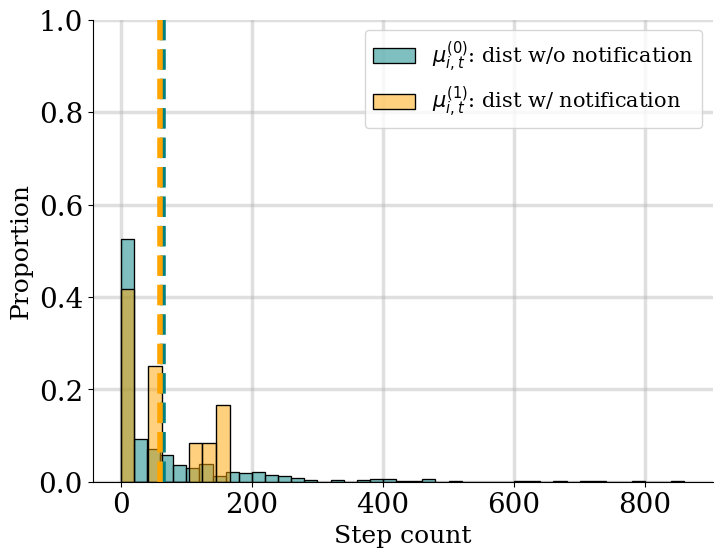

In [31]:
i, j = 23, 71

fig, ax1 = plt.subplots(figsize = (8, 6), ncols = 1)

mmd = (np.exp(mmd_KTE_estsA0[i][j]) - 1)
mhs = (np.exp(M_hs[i, j]) - 1)

#sns.kdeplot(mmd_KTE_estsA0[i][j].squeeze(), color = "teal", ax = ax1)
#sns.kdeplot(M_hs[i, j].squeeze(), color = "orange", ax = ax1)

# sns.histplot(mmd_KTE_estsA0[i][j].squeeze(), color = "teal", alpha = 0.5, stat="proportion", bins = 20)
# sns.histplot(M_hs[i, j].squeeze(), color = "orange", alpha = 0.5, stat = "proportion", bins = 20)

sns.histplot(mmd.squeeze(), color = "teal", alpha = 0.5, stat="proportion", binwidth = 20)
sns.histplot(mhs.squeeze(), color = "orange", alpha = 0.5, stat = "proportion", binwidth = 20)

# sns.histplot([-100], color = "teal", ax = ax1)
# sns.histplot([-100], color = "orange", ax=ax1)

ax1.legend(["$\mu_{i, t}^{(0)}$: dist w/o notification "] + ["$\mu_{i, t}^{(1)}$: dist w/ notification"], fontsize = 15)
ax1.set_xlabel("Step count", fontsize = 18)
ax1.set_ylabel("Proportion", fontsize = 18)
#ax1.set_title("Same mean, different distributions")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
print(np.nanmax(mmd))
print(np.nanmean(mmd) - np.nanmean(mhs))
# print(np.nanmean(mhs))

ax1.axvline(np.nanmean(mmd), color='teal', linestyle = "--", linewidth = 4) # vertical
ax1.axvline(np.nanmean(mhs), color='orange', linestyle = "--", linewidth = 4) # horizontal

#ax1.set_ylabel("")

#ax1.set_yticks(labels = [])
#ax1.set_xticks(labels = [] )

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
# ax1.set_xlim(-0.25, 6.9)
ax1.set_ylim(0, 1)


#frame1 = plt.gca()
#frame1.axes.xaxis.set_ticklabels([])
#frame1.axes.yaxis.set_ticklabels([])
#plt.show()
#ax1.set_xticks([])
#fig.suptitle("KDE of Kernel-NN$_{exp}$ synthetic vs observed sample for raw and log-transformed data")
#ks_error_ws2_estimates[ws2_i, ws2_j]
#plt.savefig("histi0_t65_reg.pdf", bbox_inches = "tight")

<Axes: ylabel='Density'>

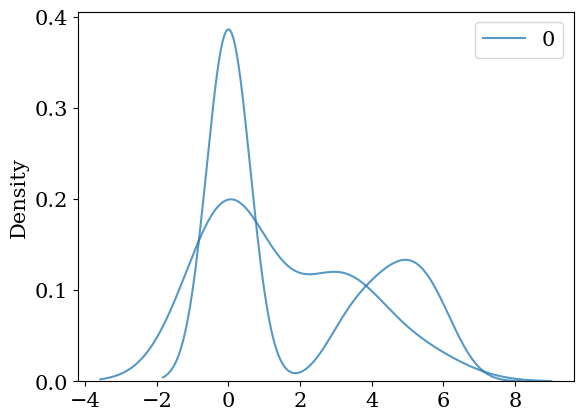

In [297]:
i, j = 0, 78
#print(mmd_KTE_estsA0[i][j])
#print(M_hs[i][j])
sns.kdeplot(mmd_KTE_estsA0[i][j], color = "purple", alpha = 0.75)
sns.kdeplot(M_hs[i, j], color = "teal", alpha = 0.75)

In [16]:
len(closeinds_obvs1_cf0)

83

In [285]:
KTE_obvs_exp = np.load("../data_checkpoints/kte_obvs_exp.npy", allow_pickle = True)

In [174]:
dnn.sqmmd_est2(mmd_KTE_estsA1[0, 0], M_hs[0, 0], kernel = "exponential")

[[nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]]


c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:57: RuntimeWarning: invalid value encountered in subtract
  kXX = np.exp( -0.5*( dXX_mm + np.transpose(dXX_mm) - 2*XX ) )


np.float64(0.0)

In [178]:
l = np.nonzero(np.isnan(KTE_obvs_exp) & ~np.isnan(ate_mmd_estimates))

In [187]:
mmd_KTE_estsA0[l[0][0]][l[1][0]]

array([[0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [4.96284463],
       [5.6094718 ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [2.7080502 ],
       [2.94443898],
       [3.25809654],
       [3.78418963],
       [4.26267988],
       [4.27666612],
       [4.39444915],
       [5.03043792],
       [0.        ],
       [0.        ],
       [0.        ],
       [2.56494936],
       [3.87120101],
       [4.33073334],
       [4.75359019],
       [4.76217393],
       [5.00394631],
       [5.26785816],
       [5.50125821],
       [6.02344759],
       [0.        ],
       [0.        ],
       [2.94443898],
       [2.94443898],
       [3.58351894],
       [3.61091791],
       [3.91202301],
       [4.20469262],
       [4.26267988],
       [4.30406509],
       [4.73619845],
       [5.225

In [185]:
print(A_hs[l[0][0], l[1][0]])
dnn.sqmmd_est2(mmd_KTE_estsA0[l[0][0], l[1][0]], M_hs[l[0][0], l[1][0]], kernel = "exponential")

1.0
[[ 1.  1.  1. ... nan nan nan]
 [ 1.  1.  1. ... nan nan nan]
 [ 1.  1.  1. ... nan nan nan]
 ...
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]]


np.float64(0.014781806988958923)

In [172]:
np.sum(M_hs[0, 0])

np.float64(nan)

In [163]:
np.sum(A_hs[0] != 2)

np.int64(189)

In [303]:
# KTE is -> A1 estimates (mmd) A0 observed and A0 estimates (mmd) A1 observed
# OR KTE is A1 estimates (mmd) A0 estimates

KTE_obvs_exp = np.full([N, T], np.nan)
KTE_ests_exp = np.full([N, T], np.nan)

#KTE_obvs_sq = np.full([N, T], np.nan)
#KTE_ests_sq = np.full([N, T], np.nan)

#KTE_obvs_ks_sq = np.full([N, T], np.nan)
#KTE_ests_ks_sq = np.full([N, T], np.nan)

KTE_obvs_ks_exp = np.full([N, T], np.nan)
KTE_ests_ks_exp = np.full([N, T], np.nan)

for i in range(N):
  for j in range(T):
    if A_hs[i, j] != 2:
    # if not mmd_estimates_exp_A0 is None and not mmd_estimates_exp_A1 is None:
      KTE_ests_exp[i, j] = dnn.sqmmd_est2(mmd_estimates_exp_A0[i][j], mmd_estimates_exp_A1[i][j], 
                                            kernel = "exponential")
      KTE_ests_ks_exp[i, j] = kstest(mmd_estimates_exp_A0[i][j], mmd_estimates_exp_A1[i][j]).statistic

      # if not mmd_estimates_sq_A0 is None and not mmd_estimates_sq_A1 is None:  
      # KTE_ests_sq[i, j] = dnn.sqmmd_est2(mmd_estimates_sq_A0[i][j], mmd_estimates_sq_A1[i][j],
      #                                     kernel = "square")
      #KTE_ests_ks_sq[i, j] = kstest(mmd_estimates_sq_A0[i][j], mmd_estimates_sq_A1[i][j]).statistic


      if A_hs[i, j] == 0:
        KTE_obvs_exp[i, j] = dnn.sqmmd_est2(mmd_estimates_exp_A1[i][j], M_hs[i, j],
                                            kernel = "exponential")
        # KTE_obvs_sq[i, j] = dnn.sqmmd_est2(mmd_estimates_sq_A1[i][j], M_hs[i, j],
        #                                   kernel = "square")

        KTE_obvs_ks_exp[i, j] = kstest(mmd_estimates_exp_A1[i][j], M_hs[i, j]).statistic
        # KTE_obvs_ks_sq[i, j] = kstest(mmd_estimates_sq_A1[i][j], M_hs[i, j]).statistic
      else:
        KTE_obvs_exp[i, j] = dnn.sqmmd_est2(M_hs[i, j], mmd_estimates_exp_A0[i][j],
                                            kernel = "exponential")
        # KTE_obvs_sq[i, j] = dnn.sqmmd_est2(M_hs[i, j], mmd_estimates_sq_A0[i][j],
        #                                   kernel = "square")

        KTE_obvs_ks_exp[i, j] = kstest(M_hs[i, j], mmd_estimates_exp_A0[i][j]).statistic
        # KTE_obvs_ks_sq[i, j] = kstest(M_hs[i, j], mmd_estimates_sq_A0[i][j]).statistic


  
  

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:58: RuntimeWarning: invalid value encountered in subtract
  kYY = np.exp( -0.5*( dYY_nn + np.transpose(dYY_nn) - 2*YY ))
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:59: RuntimeWarning: invalid value encountered in subtract
  kXY = np.exp( -0.5*( dXX_mn + dYY_mn - 2*XY ) )
C:\Users\Caleb\AppData\Local\Temp\ipykernel_14292\1803248270.py:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  KTE_ests_ks_exp[i, j] = kstest(mmd_estimates_exp_A0[i][j], mmd_estimates_exp_A1[i][j]).statistic
C:\Users\Caleb\AppData\Local\Temp\ipykernel_14292\1803248270.py:36: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecat

In [304]:
#np.save("kte_obvs_sq.npy", KTE_obvs_sq)
np.save("kte_obvs_exp_v2.npy", KTE_obvs_exp)
#np.save("kte_obvs_ks_sq.npy", KTE_obvs_ks_sq)
np.save("kte_obvs_ks_exp_v2.npy", KTE_obvs_ks_exp)

np.save("kte_ests_exp_v2.npy", KTE_ests_exp)
#np.save("kte_ests_sq.npy", KTE_ests_sq)
np.save("kte_ests_ks_exp_v2.npy", KTE_ests_ks_exp)
#np.save("kte_ests_ks_sq.npy", KTE_ests_ks_sq)



In [85]:
fig, (ax1, ax2) = plt.subplots(figsize=(16, 8), nrows = 2)


pos1 = ax1.imshow(KTE_obvs_exp, aspect = 'auto')
pos2 = ax2.imshow(KTE_obvs_ks_exp, aspect = 'auto')

fig.colorbar(pos1, ax = ax1, label = "KTE$_{gaussian}$")
fig.colorbar(pos2, ax = ax2, label = "KS-test treatment effect")

ax2.set_xlabel("Decision times")
ax2.set_ylabel("Units")

ax1.set_ylabel("Units")

ax1.get_xaxis().set_ticklabels([])
ax2.get_xaxis().set_ticklabels([])

ax1.set_title("Estimated Treatment Effect - Kernel-NN$_{gaussian}$")
#ax2.set_title("Kolmogorov-Smirnov test treatment effect")
#ax3.set_title("Kernel-NN with square kernel")

#fig.suptitle("2-sample Kolmogorov-Smirnov test statistic by DNN method")
plt.savefig("kte_ks_exp.pdf", bbox_inches = "tight")

In [116]:
len(A_hs[30][A_hs[30] == 0])


97

In [9]:
KTE_obvs_exp = np.load("../data_checkpoints/kte_obvs_exp_v2.npy")

In [10]:
# find the mean KTE across all entries

kte_mean = np.nanmean(KTE_obvs_exp)
kte_mean

np.float64(0.10141858475626934)

In [11]:
kte_median = np.nanmedian(KTE_obvs_exp)

In [43]:
kte_0_nonan = KTE_obvs_exp[11][~np.isnan(KTE_obvs_exp[11])]
kte_18_nonan = KTE_obvs_exp[12][~np.isnan(KTE_obvs_exp[12])]

In [223]:
len(kte_0_nonan)

120

In [21]:
p5_11 = np.poly1d(np.polyfit(np.arange(len(kte_11_nonan)), kte_11_nonan, deg = 5))
p5_30 = np.poly1d(np.polyfit(np.arange(len(kte_30_nonan)), kte_30_nonan, deg = 5))


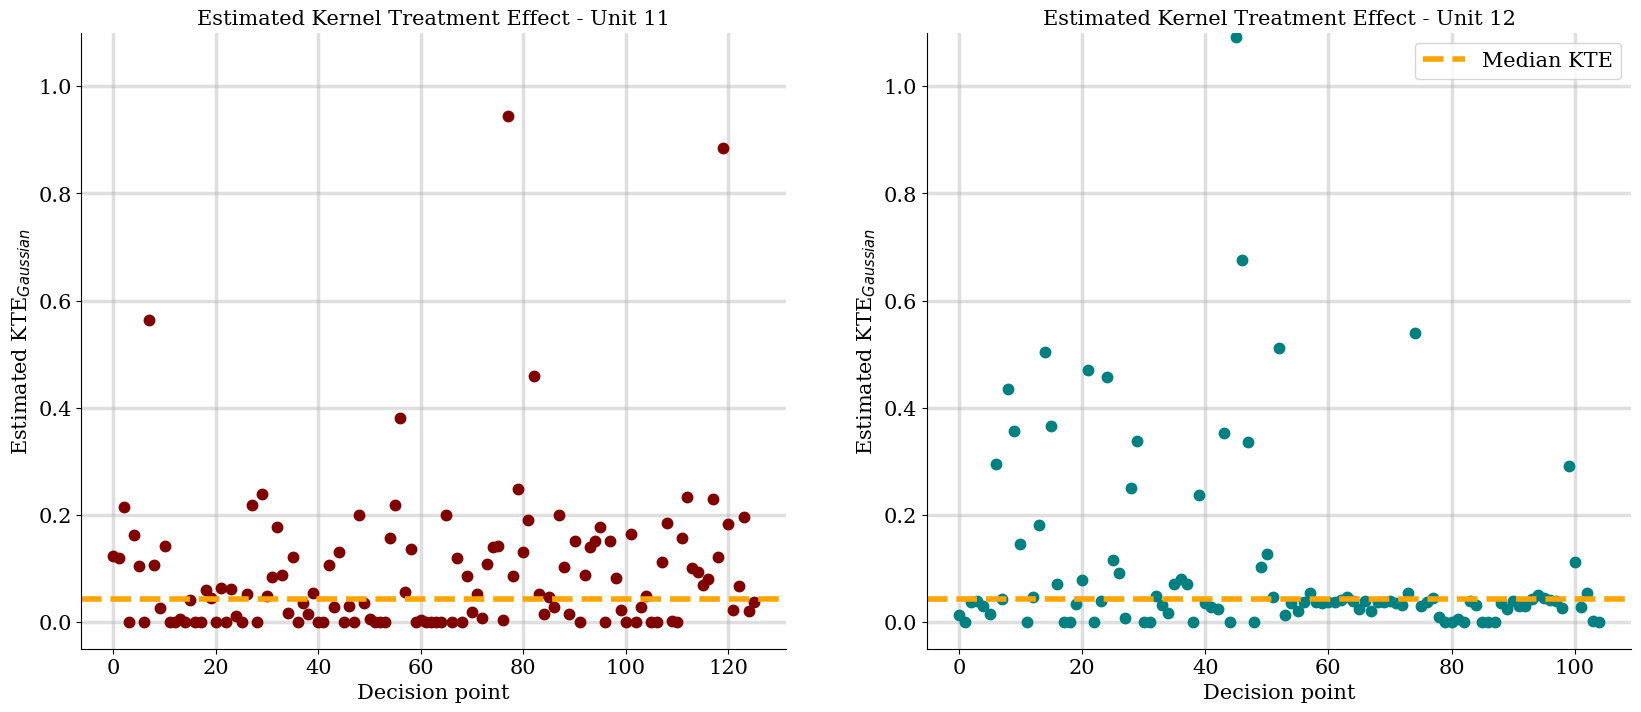

In [46]:
# unit 0
# unit 11 increases, unit 10 decreases, 
# unit 30 

fig, (ax1, ax2) = plt.subplots(figsize=(20,8), ncols = 2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
xs1 = np.arange(len(kte_0_nonan))
y1 = kte_0_nonan
ax1.plot(xs1, y1, '.', color = "maroon")
#ax1.plot(xs1, p5_11(xs1), '-', color = "orange")
#ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0], alpha= 0.8, color = "darkgreen")
ax1.set_xlabel("Decision point")
ax1.set_ylabel("Estimated KTE$_{Gaussian}$")
ax1.set_title("Estimated Kernel Treatment Effect - Unit 11")

ax1.set_ylim([-0.05, 1.1])
ax2.set_ylim([-0.05, 1.1])

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)
xs2 = np.arange(len(kte_18_nonan))
y2 = kte_18_nonan
ax2.plot(xs2, y2, '.', color = "teal")
#ax2.plot(xs2, p5_30(xs2), '-', color = "orange")
#ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0], alpha= 0.8, color = "darkgreen")
ax2.set_xlabel("Decision point")
ax2.set_ylabel("Estimated KTE$_{Gaussian}$")
ax2.set_title("Estimated Kernel Treatment Effect - Unit 12")

ax1.axhline(kte_median, linestyle='--', color = "orange", linewidth = 4.0, label = "Median KTE")
ax2.axhline(kte_median, linestyle='--', color = "orange", linewidth = 4.0, label = "Median KTE")

ax2.legend()
plt.savefig("kte_intr34_exp.pdf", bbox_inches = "tight")


<Axes: >

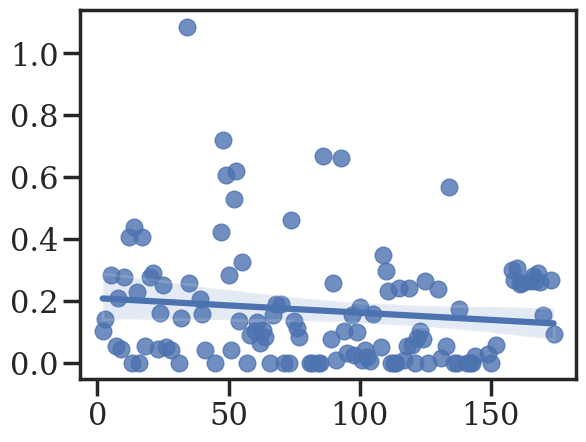

In [308]:
seaborn.regplot(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0])

(200,)


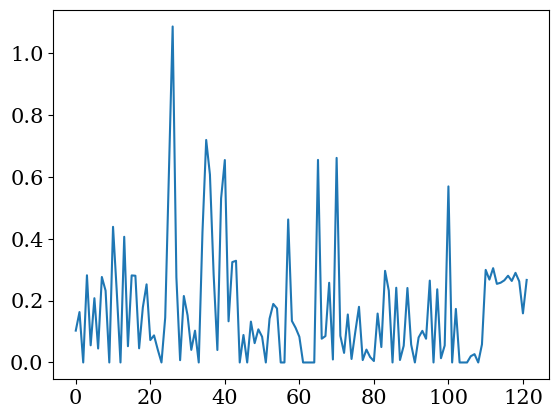

In [43]:
from scipy.interpolate import CubicSpline
print(KTE_obvs_exp[0].shape)
kte_0_nonan = KTE_obvs_exp[0][~np.isnan(KTE_obvs_exp[0])]
cs = CubicSpline(np.arange(len(kte_0_nonan)), kte_0_nonan)
x_range = np.arange(len(kte_0_nonan))
plt.plot(x_range, cs(x_range), label='Cubic Spline')

In [89]:
fig, ax = plt.subplots(figsize=(8,8))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.4)
ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_ks_exp[0], alpha= 0.8, color = "goldenrod")
ax.set_xlabel("Day in trial")
ax.set_ylabel("Kolmogorov-Smirnov test statistic")
ax.set_title("KS-test Treatment Effect - Unit 0")

plt.savefig("kte_unit0_ks.pdf", bbox_inches = "tight")

## KTE Regression with Demographic Covariates

In [75]:
from skimage.measure import block_reduce
import statsmodels.api as sm

In [10]:
KTE_obvs_exp = np.load("../data_checkpoints/kte_obvs_exp.npy")

In [52]:
user_data = pd.read_csv("../data/users.csv")


In [23]:
print(list(user_data.columns))

['user.index', 'intake.survey.utime', 'intake.survey.tz', 'intake.survey.gmtoff', 'first.notif.utime', 'first.steps.utime', 'exit.survey.utime', 'exit.survey.tz', 'exit.survey.gmtoff', 'last.notif.utime', 'last.steps.utime', 'travel.start', 'travel.end', 'dropout.date', 'totaldays', 'own.phone', 'age', 'gender', 'marital', 'marother', 'ethnicity', 'ethother', 'household.size', 'children', 'childhome', 'occupation', 'education', 'vacation', 'screentime', 'sms', 'messaging', 'call', 'email', 'calendar', 'web', 'social', 'other.mobile', 'fitapp', 'fitapp.names', 'fittracker', 'fittracker.names', 'phonecomfort', 'compcomfort', 'office.shops', 'office.pleasant', 'office.sidewalk', 'consc.detail', 'consc.prepared', 'consc.carryplans', 'consc.startwork', 'consc.wastetime', 'consc.duties', 'consc.makeplans', 'consc', 'stairs.intake', 'walk.intake', 'parkfar.intake', 'workoutbreaks.intake', 'stand.intake', 'stairs.exit', 'walk.exit', 'parkfar.exit', 'workoutbreaks.exit', 'stand.exit', 'selfeff.

In [53]:
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

In [125]:
# minus marital
keep_cols = ["user.index", "age", "gender", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

In [103]:
# minus age
keep_cols = ["user.index", "gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

In [116]:
# minus gender
keep_cols = ["user.index", "age", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

In [14]:
agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
full_agg_KTE_obvs_exp = np.nanmean(KTE_obvs_exp, axis = 1)
df_full_agg_KTE = pd.DataFrame(full_agg_KTE_obvs_exp, columns = ["trial_kte"])
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


In [13]:
full_agg_KTE_obvs_exp.shape

(37,)

In [127]:
df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)
df_kte_dem

,user.index,age,gender,ethnicity,children,education,screentime,ipaq.hepa.intake,kte_0_10,kte_10_20,kte_20_30,kte_30_40
0,1,48,female,white/caucasian,1,some college,2,3,0.219564,0.158864,0.100333,0.230792
1,2,28,male,asian/pacific islander,0,grad degree,2,2,0.100883,0.077064,0.099770,0.074421
2,3,20,female,white/caucasian,0,some college,1,3,0.076050,0.127513,0.046833,0.081199
3,4,21,male,american indian,0,some college,2,3,0.192317,0.186287,0.172570,0.178813
4,5,33,female,asian/pacific islander,0,grad degree,2,1,0.080966,0.089697,0.093770,0.057913
5,6,20,male,white/caucasian,0,some college,1,2,0.126955,0.089846,0.058379,0.176605
6,7,41,female,white/caucasian,2,grad degree,2,2,0.105728,0.140044,0.125414,0.111010
7,8,24,male,asian/pacific islander,0,grad degree,1,2,0.082939,0.068457,0.082749,0.114109
8,9,22,male,asian/pacific islander,0,some grad school,2,3,0.058351,0.081179,0.097733,0.091450
9,10,20,female,asian/pacific islander,0,college grad,2,2,0.089843,0.096467,0.103540,0.090551


In [105]:
keep_cols = ["gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)
df_kte_drop_dums

Index(['user.index', 'kte_0_10', 'kte_10_20', 'kte_20_30', 'kte_30_40',
       'gender_female', 'gender_male', 'marital_divorced/widowed/separated',
       'marital_domestic partnership', 'marital_married', 'marital_other',
       'marital_single', 'ethnicity_american indian',
       'ethnicity_asian/pacific islander', 'ethnicity_black/african american',
       'ethnicity_hispanic/latino', 'ethnicity_other',
       'ethnicity_white/caucasian', 'children_0', 'children_1', 'children_2',
       'children_3', 'children_4', 'education_college grad',
       'education_grad degree', 'education_some college',
       'education_some grad school', 'screentime_1', 'screentime_2',
       'screentime_3', 'ipaq.hepa.intake_1', 'ipaq.hepa.intake_2',
       'ipaq.hepa.intake_3'],
      dtype='object')

In [129]:
X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]


In [130]:
X_const = sm.add_constant(X)
model = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results = model.fit()

In [131]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               kte_0_10   R-squared:                       0.454
Model:                            OLS   Adj. R-squared:                 -0.092
Method:                 Least Squares   F-statistic:                    0.8319
Date:                Sun, 21 Jul 2024   Prob (F-statistic):              0.650
Time:                        16:03:08   Log-Likelihood:                 74.687
No. Observations:                  37   AIC:                            -111.4
Df Residuals:                      18   BIC:                            -80.77
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const                                0.1386      0.046      3.003      0.008       0.042       0.236
age                                 -0.0008      0.001     -0.754      0.460      -0.003       0.001
gender_male                          0.0050      0.025      0.196      0.846      -0.048       0.058
ethnicity_american indian            0.0436      0.057      0.764      0.455      -0.076       0.164
ethnicity_asian/pacific islander     0.0003      0.026      0.010      0.992      -0.055       0.056
ethnicity_black/african american     0.0134      0.044      0.306      0.763      -0.078       0.105
ethnicity_hispanic/latino            0.0049      0.055      0.089      0.930      -0.111       0.121
ethnicity_other                      0.0785      0.055      1.416      0.174      -0.038       0.195
children_1                           0.0154      0.035      0.439      0.666      -0.058       0.089
children_2                           0.0242      0.046      0.523      0.608      -0.073       0.122
children_3                           0.0405      0.045      0.891      0.385      -0.055       0.136
children_4                          -0.0069      0.061     -0.113      0.911      -0.135       0.121
education_college grad              -0.0337      0.030     -1.118      0.278      -0.097       0.030
education_grad degree               -0.0409      0.039     -1.052      0.307      -0.123       0.041
education_some grad school          -0.0515      0.035     -1.485      0.155      -0.124       0.021
screentime_2                         0.0207      0.022      0.948      0.356      -0.025       0.067
screentime_3                         0.0478      0.043      1.119      0.278      -0.042       0.138
ipaq.hepa.intake_2                   0.0039      0.024      0.160      0.875      -0.047       0.055
ipaq.hepa.intake_3                   0.0016      0.028      0.055      0.957      -0.058       0.061
==============================================================================
Omnibus:                        2.742   Durbin-Watson:                   2.003
Prob(Omnibus):                  0.254   Jarque-Bera (JB):                2.255
Skew:                           0.602   Prob(JB):                        0.324
Kurtosis:                       2.877   Cond. No.                         417.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Feature selection using AIC/BIC scores

In [139]:
# full model
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-109.15925689488844)

In [140]:
# full model - age
keep_cols = ["user.index", "gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]


X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic


c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-109.88475591470346)

In [141]:
# full model - gender
keep_cols = ["user.index", "age", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]


X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-109.65884268682021)

In [142]:
# full model - marital
keep_cols = ["user.index", "age", "gender", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]


X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic


c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-107.96821346099263)

In [143]:
# full model - ethnicity
keep_cols = ["user.index", "age", "gender", "marital", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-111.12606704901754)

In [144]:
# full model - children
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-110.39235671445998)

In [146]:
# full model - education
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "children", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "children", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-106.15640223539108)

In [147]:
# full model - screentime
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "children", "education", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "children", "education", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-109.77878981483757)

In [148]:
# full model - activity
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "children", "education", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "children", "education", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-110.78107765248122)

Removed ethnicity

In [149]:
# full model - ethnicity - age
keep_cols = ["user.index", "gender", "marital", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-111.24479309774296)

In [150]:
# full model - ethnicity - gender
keep_cols = ["user.index", "age", "marital", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = [ "marital", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = [ "marital_married", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-111.74793471568945)

In [151]:
# full model - ethnicity - marital
keep_cols = ["user.index", "age", "gender", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-112.95471346009658)

In [152]:
# full model - ethnicity - children
keep_cols = ["user.index", "age", "gender", "marital", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-111.48102192865386)

In [153]:
# full model - ethnicity - education
keep_cols = ["user.index", "age", "gender", "marital", "children", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "children", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "children_0",  "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-110.14986448776611)

In [154]:
# full model - ethnicity - screentime
keep_cols = ["user.index", "age", "gender", "marital", "children", "education", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "children", "education", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "children_0", "education_some college", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-110.96733600900959)

In [155]:
# full model - ethnicity - activity
keep_cols = ["user.index", "age", "gender", "marital", "children", "education", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "children", "education", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "children_0", "education_some college", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-112.85082353894475)

In [156]:
# full model - ethnicity - marital - age
keep_cols = ["user.index", "gender", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-111.46304574128558)

In [157]:
# full model - ethnicity - marital - gender
keep_cols = ["user.index", "age", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-113.8159370937225)

In [158]:
# full model - ethnicity - marital - children
keep_cols = ["user.index", "age", "gender", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-112.23301848230314)

In [159]:
# full model - ethnicity - marital - education
keep_cols = ["user.index", "age", "gender", "children", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-114.5435057993329)

In [160]:
# full model - ethnicity - marital - screentime
keep_cols = ["user.index", "age", "gender", "children", "education",  "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-113.29031115554832)

In [161]:
# full model - ethnicity - marital - activity
keep_cols = ["user.index", "age", "gender", "children", "education", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-114.92124141801114)

Remove ethnicity, marital, and activity

In [162]:
# full model - ethnicity - marital - activity - age
keep_cols = ["user.index", "gender", "children", "education", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-113.67707008936645)

In [163]:
# full model - ethnicity - marital - activity - gender
keep_cols = ["user.index", "age", "children", "education", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["children", "education", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["children_0", "education_some college", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-113.45669411245449)

In [164]:
# full model - ethnicity - marital - activity - children
keep_cols = ["user.index", "age", "gender","education", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "education", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "education_some college", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-114.55861989302076)

In [165]:
# full model - ethnicity - marital - activity - education
keep_cols = ["user.index", "age", "gender", "children", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-115.42913392255541)

In [166]:
# full model - ethnicity - marital - activity - screentime
keep_cols = ["user.index", "age", "gender", "children", "education"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-115.79680408403307)

Remove ethnicity, marital, activity, screentime

In [167]:
# full model - ethnicity - marital - activity - screentime - age
keep_cols = ["user.index", "gender", "children", "education"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-115.01902834793076)

In [168]:
# full model - ethnicity - marital - activity - screentime - gender
keep_cols = ["user.index", "age", "children", "education"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["children", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = [ "children_0", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-114.33990503755015)

In [169]:
# full model - ethnicity - marital - activity - screentime - children
keep_cols = ["user.index", "age", "gender", "education"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-116.31049505007074)

In [170]:
# full model - ethnicity - marital - activity - screentime - education
keep_cols = ["user.index", "age", "gender", "children"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-115.49551890647162)

Minus ethnicity, marital, activity, screentime, children

In [171]:
# full model - ethnicity - marital - activity - screentime - children - age
keep_cols = ["user.index", "gender", "education"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-117.59436895732168)

In [174]:
# full model - ethnicity - marital - activity - screentime - children - gender
keep_cols = ["user.index", "age", "education"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-116.3065485405525)

In [175]:
# full model - ethnicity - marital - activity - screentime - children - education
keep_cols = ["user.index", "age", "gender"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-117.9036952552568)

In [178]:
# full model - ethnicity - marital - activity - screentime - children - education - age
keep_cols = ["user.index", "gender"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-119.06722035645831)

In [179]:
# full model - ethnicity - marital - activity - screentime - children - education - gender
keep_cols = ["user.index", "age"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = []

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = []

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-118.4101925027887)

In [20]:
# full model - ethnicity - marital - activity - screentime - children - education - age
keep_cols = ["user.index"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = []

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = []

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


np.float64(-119.43024443468491)

In [25]:
print(results_20_30.summary())

                            OLS Regression Results                            
Dep. Variable:              kte_20_30   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                       nan
Date:                Mon, 22 Jul 2024   Prob (F-statistic):                nan
Time:                        09:45:33   Log-Likelihood:                 61.275
No. Observations:                  36   AIC:                            -120.5
Df Residuals:                      35   BIC:                            -119.0
Df Model:                           0                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0995      0.007     13.348      0.0

Minimized AIC is the null model

In [1]:
# fit against full averaged


hel


### Full model on full averaged KTE

In [ ]:
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]


In [194]:
user_data_final["gender"]

0     female
1       male
2     female
3       male
4     female
5       male
6     female
7       male
8       male
9     female
10    female
11      male
12    female
13    female
14    female
15      male
16    female
17    female
18      male
19    female
20      male
21    female
22    female
23    female
24    female
25    female
26    female
27      male
28      male
29      male
30      male
31    female
32    female
33    female
34    female
35    female
36    female
Name: gender, dtype: object

In [228]:
X.values.astype(int)

array([[48,  1,  2,  3,  1,  1,  1,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0],
       [28,  0,  2,  2,  1,  1,  1,  0,  0,  0,  0,  1,  0,  1,  0,  0,
         0,  0,  1,  0],
       [20,  0,  1,  3,  2,  1,  1,  0,  0,  0,  1,  0,  0,  0,  0,  0,
         0,  0,  0,  0],
       [21,  0,  2,  3,  1,  1,  1,  0,  0,  0,  1,  1,  1,  0,  0,  0,
         0,  0,  0,  0],
       [33,  0,  2,  1,  1,  2,  1,  0,  0,  0,  1,  0,  0,  1,  0,  0,
         0,  0,  1,  0],
       [20,  0,  1,  2,  4,  3,  3,  0,  0,  0,  1,  1,  0,  0,  0,  0,
         0,  0,  0,  0],
       [41,  2,  2,  2,  2,  2,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  1,  0],
       [24,  0,  1,  2,  1,  2,  2,  0,  0,  0,  1,  1,  0,  1,  0,  0,
         0,  0,  1,  0],
       [22,  0,  2,  3,  1,  1,  1,  0,  0,  0,  1,  1,  0,  1,  0,  0,
         0,  0,  0,  1],
       [20,  0,  2,  2,  4,  3,  2,  0,  0,  0,  1,  0,  0,  1,  0,  0,
         0,  1,  0,  0],
       [19,  0,  1,  2,  3,  2

In [238]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values.astype(int), i) for i in range(X.shape[1])]
print(vif_data)

                               feature        VIF
0                                  age  13.356081
1                            childhome   4.145997
2                           screentime  11.882819
3                     ipaq.hepa.intake  11.575347
4                         office.shops  10.245923
5                      office.pleasant  12.170847
6                      office.sidewalk  14.090394
7   marital_divorced/widowed/separated   1.859918
8         marital_domestic partnership   2.024379
9                        marital_other   1.929643
10                      marital_single   6.941379
11                         gender_male   3.544534
12           ethnicity_american indian   1.442889
13    ethnicity_asian/pacific islander   3.888784
14    ethnicity_black/african american   1.852872
15           ethnicity_hispanic/latino   1.604981
16                     ethnicity_other   1.582795
17              education_college grad   4.435005
18               education_grad degree   8.651274


In [271]:
# full model
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "childhome", "education", "screentime", "ipaq.hepa.intake", "office.shops", "office.pleasant", "office.sidewalk"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = [ "marital", "gender", "ethnicity", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["marital_married", "gender_female", "ethnicity_white/caucasian", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

Y_kte = df_full_agg_KTE["trial_kte"]

X_const = sm.add_constant(X)
model = sm.OLS(Y_kte, X_const.astype('float64'), missing = 'drop')
results = model.fit()

print(results.summary())


                            OLS Regression Results                            
Dep. Variable:              trial_kte   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.162
Method:                 Least Squares   F-statistic:                     1.348
Date:                Tue, 23 Jul 2024   Prob (F-statistic):              0.275
Time:                        13:58:21   Log-Likelihood:                 88.606
No. Observations:                  37   AIC:                            -135.2
Df Residuals:                      16   BIC:                            -101.4
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
cons

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\skimage\measure\block.py:94: RuntimeWarning: Mean of empty slice
  return func(blocked, axis=tuple(range(image.ndim, blocked.ndim)), **func_kwargs)


In [125]:
import seaborn as sns

In [272]:
def coef_plot(results):
  """
  Plot coefficients with 95% confidence interval
  """
  # extract coef and ci from results summary
  coefs = pd.DataFrame(results.summary().tables[1].data)
  # col names are the first row
  coefs.columns = coefs.iloc[0]
  # drop the col names
  coefs = coefs.drop(0)
  coefs = coefs.set_index(coefs.columns[0])
  coefs = coefs.astype(float)
  err = coefs["coef"] - coefs["[0.025"]
  coefs["errors"] = err

  # drop const for plot
  coefs = coefs.drop(['const'])
  # sort aascending
  coefs = coefs.sort_values(by = ['coef'])
  
  vars = list(coefs.index.values)

  coefs['vars'] = vars

  sns.set_context("poster")

  fig, ax = plt.subplots(figsize = (15, 10))
  
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)

  coefs.plot(x = 'vars', y = 'coef', kind = "bar", 
             ax = ax, color = 'none', ecolor = 'teal', capsize = 5, 
             yerr = 'errors', legend = False)
  ax.set_title("Feature coefficients with 95% CI - Mean KTE regression")
  ax.set_ylabel("Coefficients")
  ax.set_xlabel("Features")

  plt.xticks(rotation=60, ha='right')

  ax.scatter(x = np.arange(coefs.shape[0]),
             marker = 'o', s = 80, y = coefs['coef'], color = 'teal')
  # line at 0
  ax.axhline(y=0, linestyle = '--', color = 'orange', linewidth = 1)  
  ax.grid(True, alpha=0.4)

  plt.savefig("kte_regression_coefs_mean.pdf", bbox_inches = "tight")


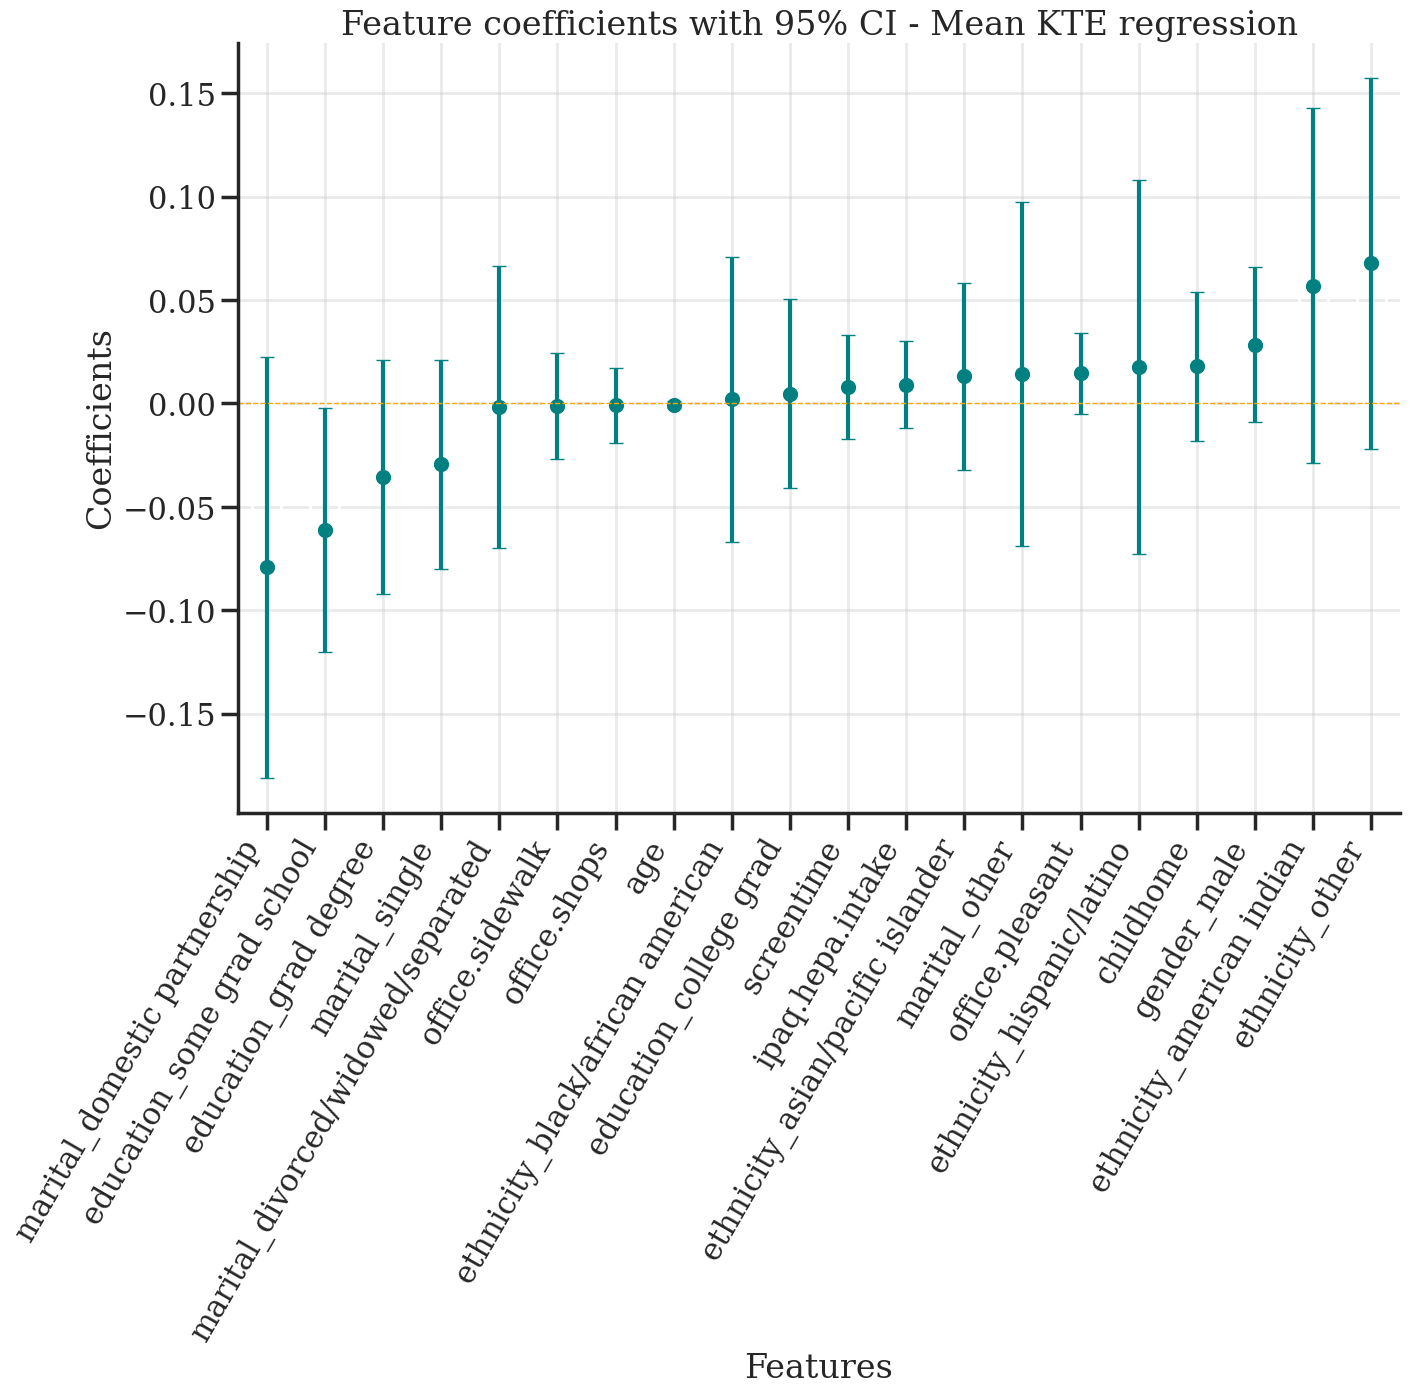

In [273]:
coef_plot(results)

## Interestingness

In [6]:
KTE_obvs_exp = np.load('../data_checkpoints/kte_obvs_exp_v2.npy')

In [23]:
# find the mean KTE across all entries

kte_mean = np.nanmean(KTE_obvs_exp)
kte_mean

np.float64(0.10141858475626934)

In [24]:
kte_median = np.nanmedian(KTE_obvs_exp)
kte_median

np.float64(0.04219301654122931)

In [25]:
split_kte =np.split(KTE_obvs_exp, 2, axis = 1)
beg_kte = split_kte[0]
end_kte = split_kte[1]


In [26]:
beg_kte_gt_median = beg_kte > kte_median
end_kte_gt_median = end_kte > kte_median

beg_kte_lt_median = beg_kte < kte_median
end_kte_lt_median = end_kte < kte_median

count_beg_kte_gt_median = np.sum(beg_kte_gt_median, axis = 1)
count_end_kte_gt_median = np.sum(end_kte_gt_median, axis = 1)

count_beg_kte_lt_median = np.sum(beg_kte_lt_median, axis = 1)
count_end_kte_lt_median = np.sum(end_kte_lt_median, axis = 1)

count_beg_kte_gt_median


array([51, 30, 23, 32, 29, 26, 44, 23, 32, 49, 29, 29, 31, 39, 27, 26, 22,
       28, 27, 18, 32, 25, 37, 44, 28, 33, 38, 22, 24, 41, 33, 31, 32, 29,
       37, 32, 30])

In [27]:
beg_kte_total_nonan = np.sum(~np.isnan(beg_kte), axis = 1)
end_kte_total_nonan = np.sum(~np.isnan(end_kte), axis = 1)

beg_kte_gt_prop = count_beg_kte_gt_median / beg_kte_total_nonan
end_kte_gt_prop = count_end_kte_gt_median / end_kte_total_nonan

beg_kte_lt_prop = count_beg_kte_lt_median / beg_kte_total_nonan
end_kte_lt_prop = count_end_kte_lt_median / end_kte_total_nonan

C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\2462365331.py:5: RuntimeWarning: invalid value encountered in divide
  end_kte_gt_prop = count_end_kte_gt_median / end_kte_total_nonan
C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\2462365331.py:8: RuntimeWarning: invalid value encountered in divide
  end_kte_lt_prop = count_end_kte_lt_median / end_kte_total_nonan


In [34]:
# interestingness 1
inds_i1 = np.nonzero((beg_kte_gt_prop > 0.6) & (end_kte_gt_prop > 0.6))
inds_i2 = np.nonzero((beg_kte_lt_prop > 0.6) & (end_kte_lt_prop > 0.6))
inds_i3 = np.nonzero((beg_kte_gt_prop < 0.5) & (end_kte_gt_prop > 0.5))
inds_i4 = np.nonzero((beg_kte_lt_prop < 0.5) & (end_kte_lt_prop > 0.5))
print(inds_i1)
print(inds_i2)
print(inds_i3)
print(inds_i4)

(array([ 0,  3, 35]),)
(array([18, 21]),)
(array([ 4,  8, 11, 16, 26, 27]),)
(array([ 5,  9, 12, 13, 17, 22, 25, 34]),)


In [69]:
# inds_i1-4 represent the "interesting" cohort. 
# we regress wrt to the binary outcome for each of them
is_intr_1 = np.zeros(N)
is_intr_1[inds_i1] = 1

is_intr_2 = np.zeros(N)
is_intr_2[inds_i2] = 1

is_intr_3 = np.zeros(N) 
is_intr_3[inds_i3] = 1

is_intr_4 = np.zeros(N)
is_intr_4[inds_i4] = 1



In [70]:
# Interestingness with magnitude
# compute residuals wrt to the median for the first and second halves

beg_kte_resid_mean = np.nanmean(beg_kte - kte_mean, axis = 1)
end_kte_resid_mean = np.nanmean(end_kte - kte_mean, axis = 1)

end_kte_resid_mean

C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\3719485309.py:5: RuntimeWarning: Mean of empty slice
  end_kte_resid_mean = np.nanmean(end_kte - kte_mean, axis = 1)


array([ 0.0334508 , -0.00776636, -0.03791742,  0.07789822, -0.02440362,
        0.01526868,  0.01633912, -0.00198622, -0.00668207, -0.0052181 ,
       -0.00608646,  0.01391516, -0.05391018, -0.0229748 ,  0.00226369,
       -0.0040572 ,  0.06078923, -0.02597062, -0.03944293, -0.05115129,
        0.00250644, -0.05161485, -0.03002543,  0.05801081,  0.00048982,
        0.0015357 , -0.05130383,  0.03782211,         nan,  0.11061234,
       -0.00230669, -0.01822916, -0.00664808, -0.04955327, -0.01817205,
        0.03483454, -0.00510519])

In [71]:
inds_resid_i1 = np.nonzero((beg_kte_resid_mean > 0.05) & (end_kte_resid_mean > 0.05))
inds_resid_i2 = np.nonzero((beg_kte_resid_mean < -0.05) & (end_kte_resid_mean < -0.05))
inds_resid_i3 = np.nonzero((beg_kte_resid_mean < 0) & (end_kte_resid_mean > 0))
inds_resid_i4 = np.nonzero((beg_kte_resid_mean > 0) & (end_kte_resid_mean < 0))

print(inds_resid_i1)
print(inds_resid_i2)
print(inds_resid_i3)
print(inds_resid_i4)


(array([ 3, 23, 29]),)
(array([19, 21]),)
(array([11, 25]),)
(array([12, 13, 26, 30]),)


In [137]:
kte_0_nonan = KTE_obvs_exp[12][~np.isnan(KTE_obvs_exp[12])]
kte_18_nonan = KTE_obvs_exp[13][~np.isnan(KTE_obvs_exp[13])]

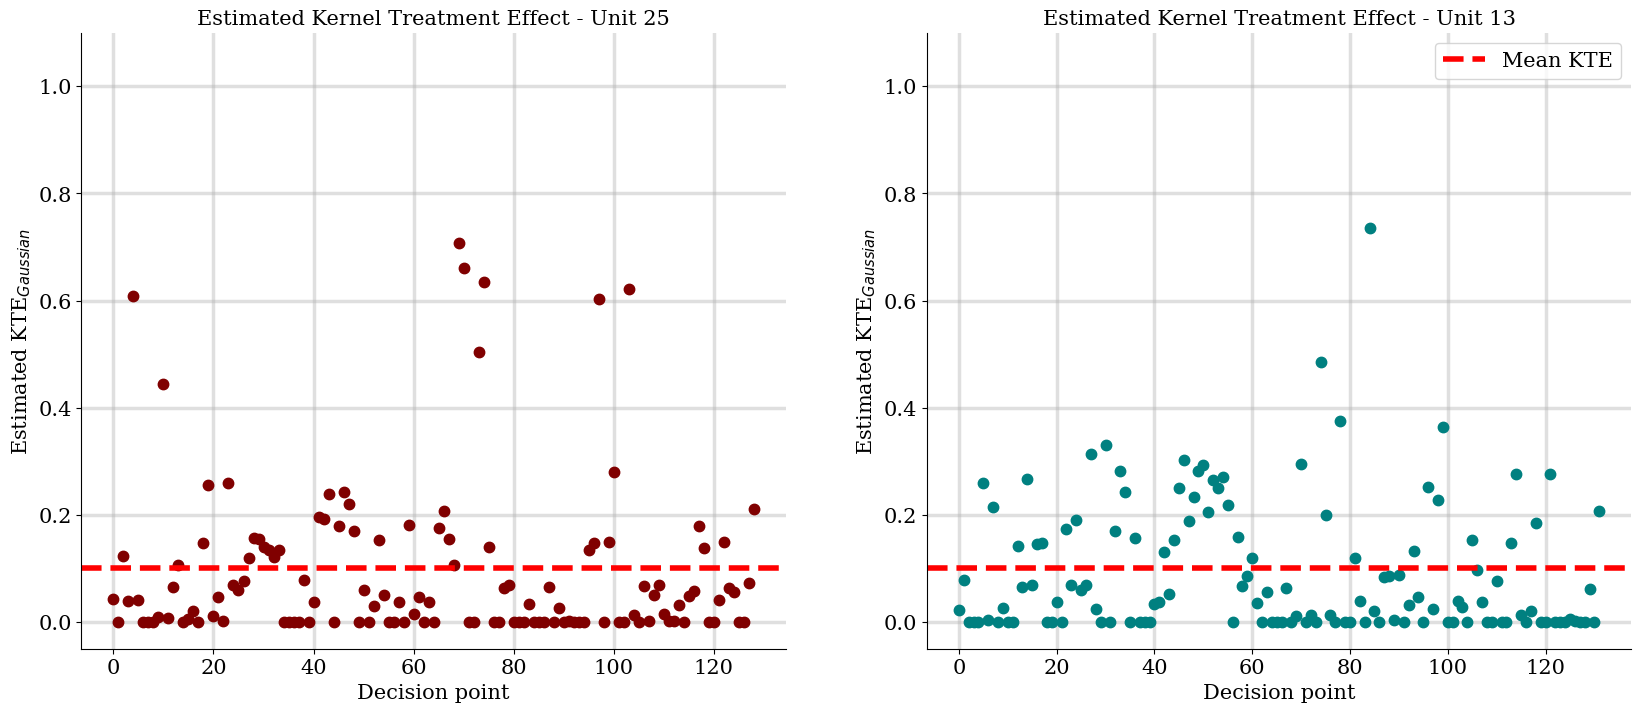

In [65]:
# unit 0
# unit 11 increases, unit 10 decreases, 
# unit 30 

fig, (ax1, ax2) = plt.subplots(figsize=(20,8), ncols = 2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
xs1 = np.arange(len(kte_0_nonan))
y1 = kte_0_nonan
ax1.plot(xs1, y1, '.', color = "maroon")
#ax1.plot(xs1, p5_11(xs1), '-', color = "orange")
#ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0], alpha= 0.8, color = "darkgreen")
ax1.set_xlabel("Decision point")
ax1.set_ylabel("Estimated KTE$_{Gaussian}$")
ax1.set_title("Estimated Kernel Treatment Effect - Unit 25")

ax1.set_ylim([-0.05, 1.1])
ax2.set_ylim([-0.05, 1.1])

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)
xs2 = np.arange(len(kte_18_nonan))
y2 = kte_18_nonan
ax2.plot(xs2, y2, '.', color = "teal")
#ax2.plot(xs2, p5_30(xs2), '-', color = "orange")
#ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0], alpha= 0.8, color = "darkgreen")
ax2.set_xlabel("Decision point")
ax2.set_ylabel("Estimated KTE$_{Gaussian}$")
ax2.set_title("Estimated Kernel Treatment Effect - Unit 13")

ax1.axhline(kte_mean, linestyle='--', color = "red", linewidth = 4.0, label = "Mean KTE")
ax2.axhline(kte_mean, linestyle='--', color = "red", linewidth = 4.0, label = "Mean KTE")

ax2.legend()
plt.savefig("kte_resid34_exp.pdf", bbox_inches = "tight")


In [73]:
is_resid_1 = np.zeros(N)
is_resid_1[inds_resid_i1] = 1

is_resid_2 = np.zeros(N)
is_resid_2[inds_resid_i2] = 1

is_resid_3 = np.zeros(N) 
is_resid_3[inds_resid_i3] = 1

is_resid_4 = np.zeros(N)
is_resid_4[inds_resid_i4] = 1

In [67]:
user_data = pd.read_csv("../data/users.csv")


In [109]:
# full model
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "childhome", "education", "screentime", "ipaq.hepa.intake", "office.shops", "office.pleasant", "office.sidewalk", "phonecomfort"]
df_kte_dem = user_data[keep_cols]

#agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
#df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem["intr_1"] = is_intr_1
df_kte_dem["intr_2"] = is_intr_2
df_kte_dem["intr_3"] = is_intr_3
df_kte_dem["intr_4"] = is_intr_4

df_kte_dem["resid_1"] = is_resid_1
df_kte_dem["resid_2"] = is_resid_2
df_kte_dem["resid_3"] = is_resid_3
df_kte_dem["resid_4"] = is_resid_4


keep_cols = [ "marital", "gender", "ethnicity", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["marital_married", "gender_female", "ethnicity_white/caucasian", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["intr_1", "intr_2", "intr_3", "intr_4", 
                                     "resid_1", "resid_2", "resid_3", "resid_4", 
                                     "user.index"])

Y_kte_intr_1 = df_kte_drop_dums["intr_1"]
Y_kte_intr_2 = df_kte_drop_dums["intr_2"]
Y_kte_intr_3 = df_kte_drop_dums["intr_3"]
Y_kte_intr_4 = df_kte_drop_dums["intr_4"]

Y_kte_resid_1 = df_kte_drop_dums["resid_1"]
Y_kte_resid_2 = df_kte_drop_dums["resid_2"]
Y_kte_resid_3 = df_kte_drop_dums["resid_3"]
Y_kte_resid_4 = df_kte_drop_dums["resid_4"]

#Y_kte = df_full_agg_KTE["trial_kte"]

X_const = sm.add_constant(X)
model = sm.OLS(Y_kte_resid_4, X_const.astype('float64'), missing = 'drop')
results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                resid_4   R-squared:                       0.639
Model:                            OLS   Adj. R-squared:                  0.133
Method:                 Least Squares   F-statistic:                     1.263
Date:                Tue, 30 Jul 2024   Prob (F-statistic):              0.326
Time:                        10:15:33   Log-Likelihood:                 9.6077
No. Observations:                  37   AIC:                             24.78
Df Residuals:                      15   BIC:                             60.22
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
cons

C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\4194503788.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_kte_dem["intr_1"] = is_intr_1
C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\4194503788.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_kte_dem["intr_2"] = is_intr_2
C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\4194503788.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See

In [110]:
X

,age,childhome,screentime,ipaq.hepa.intake,office.shops,office.pleasant,office.sidewalk,phonecomfort,marital_divorced/widowed/separated,marital_domestic partnership,...,marital_single,gender_male,ethnicity_american indian,ethnicity_asian/pacific islander,ethnicity_black/african american,ethnicity_hispanic/latino,ethnicity_other,education_college grad,education_grad degree,education_some grad school
0,48,0,2,3,1,1,1,4,False,False,...,False,False,False,False,False,False,False,False,False,False
1,28,0,2,2,1,1,1,5,False,False,...,False,True,False,True,False,False,False,False,True,False
2,20,0,1,3,2,1,1,5,False,False,...,True,False,False,False,False,False,False,False,False,False
3,21,0,2,3,1,1,1,5,False,False,...,True,True,True,False,False,False,False,False,False,False
4,33,0,2,1,1,2,1,5,False,False,...,True,False,False,True,False,False,False,False,True,False
5,20,0,1,2,4,3,3,4,False,False,...,True,True,False,False,False,False,False,False,False,False
6,41,2,2,2,2,2,2,5,False,False,...,False,False,False,False,False,False,False,False,True,False
7,24,0,1,2,1,2,2,5,False,False,...,True,True,False,True,False,False,False,False,True,False
8,22,0,2,3,1,1,1,5,False,False,...,True,True,False,True,False,False,False,False,False,True
9,20,0,2,2,4,3,2,5,False,False,...,True,False,False,True,False,False,False,True,False,False


In [111]:
def coef_plot(results):
  """
  Plot coefficients with 95% confidence interval
  """
  # extract coef and ci from results summary
  coefs = pd.DataFrame(results.summary().tables[1].data)
  # col names are the first row
  coefs.columns = coefs.iloc[0]
  # drop the col names
  coefs = coefs.drop(0)
  coefs = coefs.set_index(coefs.columns[0])
  coefs = coefs.astype(float)
  err = coefs["coef"] - coefs["[0.025"]
  coefs["errors"] = err

  # drop const for plot
  coefs = coefs.drop(['const'])
  # sort aascending
  coefs = coefs.sort_values(by = ['coef'])
  
  vars = list(coefs.index.values)

  coefs['vars'] = vars

  sns.set_context("poster")

  fig, ax = plt.subplots(figsize = (15, 10))
  
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)

  coefs.plot(x = 'vars', y = 'coef', kind = "bar", 
             ax = ax, color = 'none', ecolor = 'teal', capsize = 5, 
             yerr = 'errors', legend = False)
  ax.set_title("Feature coefficients with 95% CI - Residual Type 4 logit")
  ax.set_ylabel("Coefficients")
  ax.set_xlabel("Features")

  plt.xticks(rotation=60, ha='right')

  ax.scatter(x = np.arange(coefs.shape[0]),
             marker = 'o', s = 80, y = coefs['coef'], color = 'teal')
  # line at 0
  ax.axhline(y=0, linestyle = '--', color = 'orange', linewidth = 1)  
  ax.grid(True, alpha=0.4)
  plt.savefig("kte_logits_coefs_resid4.pdf", bbox_inches = "tight")


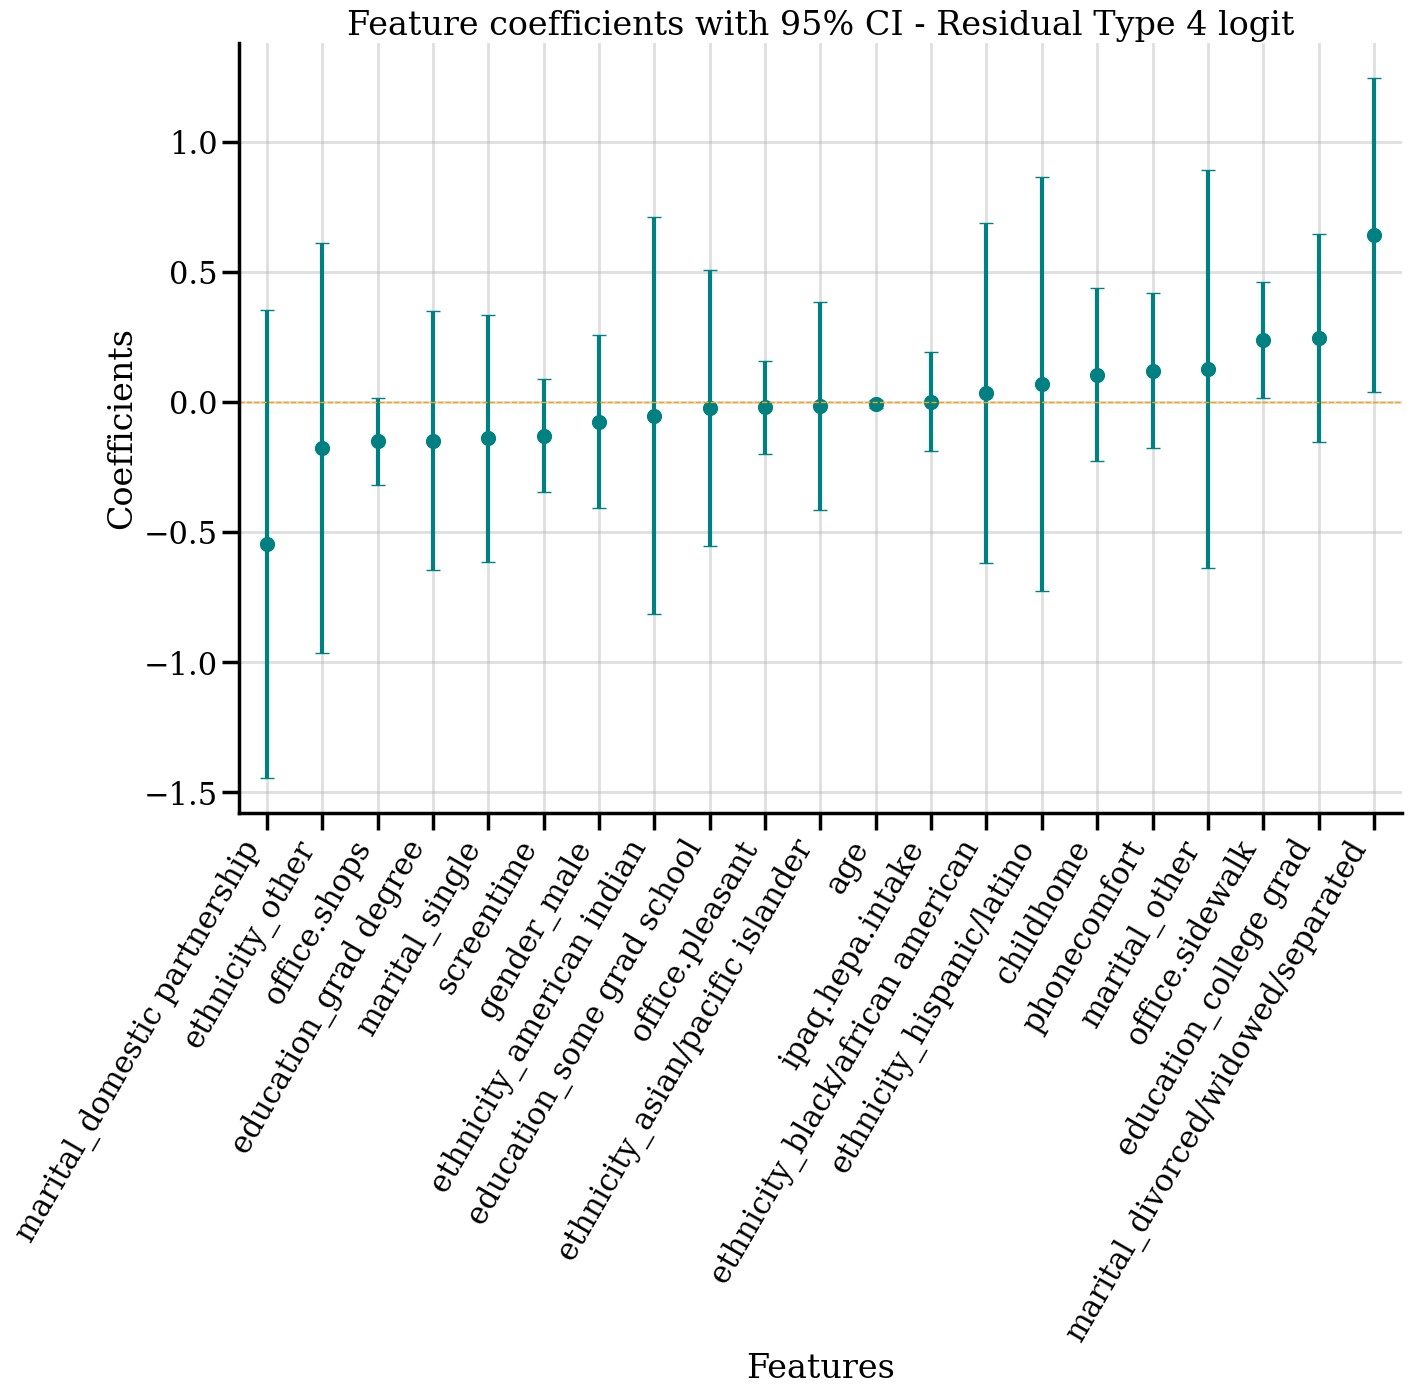

In [112]:
coef_plot(results)

### Computing Entry-level Average Treatment Effect

In [113]:
mmd_estimates_exp_A1 = np.load("../data_checkpoints/mmd_exp_fullestimatesA1_v20_log.npy", allow_pickle = True)
mmd_estimates_exp_A0 = np.load("../data_checkpoints/mmd_exp_fullestimatesA0_v20_log.npy", allow_pickle = True)

(120, 1)

In [114]:
mean_mmd_estimates_exp_A1 = np.full([N, T], np.nan)
mean_mmd_estimates_exp_A0 = np.full([N, T], np.nan)

for i in range(N):
  for j in range(T):
    if A_hs[i, j] != 2:
      mean_mmd_estimates_exp_A1[i, j] = np.nanmean(mmd_estimates_exp_A1[i][j], axis = 0)
      mean_mmd_estimates_exp_A0[i, j] = np.nanmean(mmd_estimates_exp_A0[i][j], axis = 0)


C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\736470486.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mean_mmd_estimates_exp_A1[i, j] = np.nanmean(mmd_estimates_exp_A1[i][j], axis = 0)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\736470486.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  mean_mmd_estimates_exp_A0[i, j] = np.nanmean(mmd_estimates_exp_A0[i][j], axis = 0)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\736470486.py:8: RuntimeWarning: Mean of empty slice
  mean_mmd_estimates_exp_A0[i, j] = np.nanmean(mmd_estimates_exp_A0[i][j], axis = 0)


In [227]:
dnn.sqmmd_est2(np.array([[np.nan], [1.], [2.]]), np.array([[np.nan], [3.], [9.]]), kernel = "exponential")

np.float64(0.0373177932092808)

In [115]:
ate_mmd_estimates = np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    if A_hs[i, j] != 2:
      if A_hs[i, j] == 1:
        ate_mmd_estimates[i, j] = mean_mmd_estimates_exp_A0[i][j] - M_hs_log_mean[i, j]
      else:
        ate_mmd_estimates[i, j] = mean_mmd_estimates_exp_A1[i][j] - M_hs_log_mean[i, j]



C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\175719431.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  ate_mmd_estimates[i, j] = mean_mmd_estimates_exp_A1[i][j] - M_hs_log_mean[i, j]
C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\175719431.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  ate_mmd_estimates[i, j] = mean_mmd_estimates_exp_A0[i][j] - M_hs_log_mean[i, j]


In [189]:
np.sum(ate_mmd_estimates < 0)

np.int64(2561)

Defining interestingness wrt to scalar ATE

1. Type 1: fraction of positive ATE is greater than some threshold for both the first half and second half of the study (positive effect)
2. Type 2: fraction of positive ATE is less than some threshold for both the first half and second half of the study (negative effect)
   1. Since we think our treatment will have 0 ate at minimum, having 0.5 proportion of negative ate is sufficient for "interesting"
3. Type 3: fraction of negative ATE is greater than some threshold for the first half but below some threshold for the second half (increasing effect)
4. Type 4: fraction of positive ATE is greater than some threshold for the first half but below some threshold for the second half (decreasing effect)

In [135]:
ate_0_nonan = ate_mmd_estimates[0][~np.isnan(ate_mmd_estimates[0])]
ate_0_nonan = ate_0_nonan[0:105]
ate_18_nonan = ate_mmd_estimates[12][~np.isnan(ate_mmd_estimates[12])]
ate_18_nonan = ate_18_nonan[0:105]

In [132]:
len(ate_0_nonan)

105

In [129]:
len(kte_0_nonan)

105

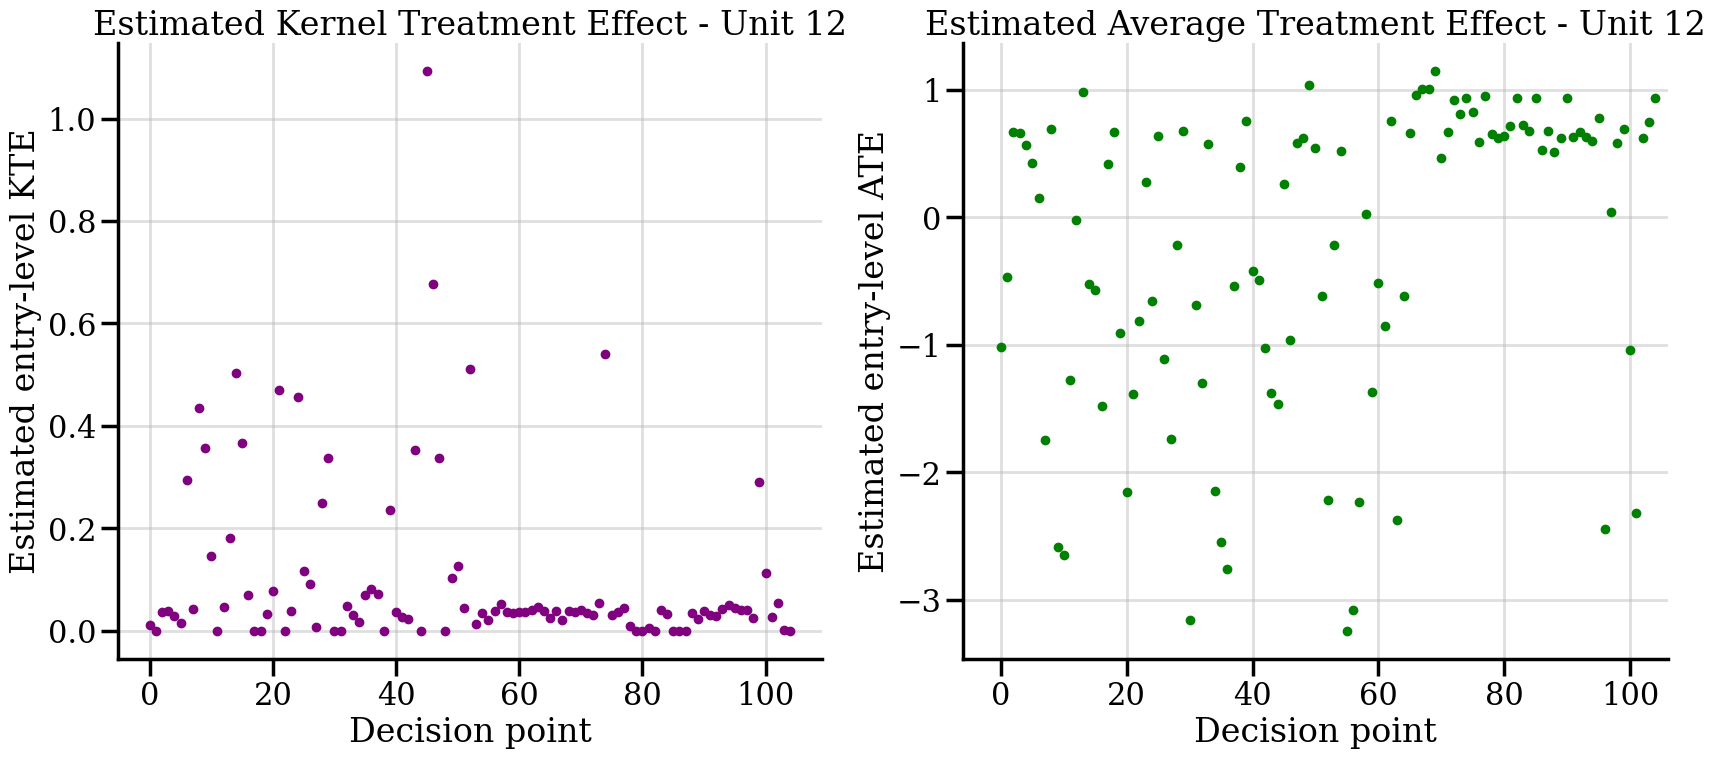

In [140]:
fig, (ax1, ax2) = plt.subplots(figsize=(20,8), ncols = 2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
xs1 = np.arange(len(kte_0_nonan))
y1 = kte_0_nonan
ax1.plot(xs1, y1, '.', color = "purple")
#ax1.plot(xs1, p5_11(xs1), '-', color = "orange")
#ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0], alpha= 0.8, color = "darkgreen")
ax1.set_xlabel("Decision point")
ax1.set_ylabel("Estimated entry-level KTE")
ax1.set_title("Estimated Kernel Treatment Effect - Unit 12")

ax2.set_xlim([-6, 106])
#ax2.set_ylim([0, 1.1])

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)
xs2 = np.arange(len(ate_18_nonan))
y2 = ate_18_nonan
ax2.plot(xs2, y2, '.', color = "green")
#ax2.plot(xs2, p5_30(xs2), '-', color = "orange")
#ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0], alpha= 0.8, color = "darkgreen")
ax2.set_xlabel("Decision point")
ax2.set_ylabel("Estimated entry-level ATE")
ax2.set_title("Estimated Average Treatment Effect - Unit 12")

#plt.show()
#ax1.axhline(kte_median, linestyle='--', color = "orange", linewidth = 4.0)
#ax2.axhline(kte_median, linestyle='--', color = "orange", linewidth = 4.0)
plt.savefig("kte_ate_unit12_exp.pdf", bbox_inches = "tight")


In [199]:
ate_mmd_estimates.shape

(37, 200)

In [141]:
split_ate = np.split(ate_mmd_estimates, 2, axis = 1)
beg_ate = split_ate[0]
end_ate = split_ate[1]

pos_beg_ate = np.sum(beg_ate > 0, axis = 1)
pos_end_ate = np.sum(end_ate > 0, axis = 1)

neg_beg_ate = np.sum(beg_ate < 0, axis = 1)
neg_end_ate = np.sum(end_ate < 0, axis = 1)

tot_beg_ate = np.sum(~np.isnan(beg_ate), axis = 1)
tot_end_ate = np.sum(~np.isnan(end_ate), axis = 1)

pos_beg_ate_prop = pos_beg_ate / tot_beg_ate
pos_end_ate_prop = pos_end_ate / tot_end_ate

neg_beg_ate_prop = neg_beg_ate / tot_beg_ate
neg_end_ate_prop = neg_end_ate / tot_end_ate

pos_beg_ate_prop


C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\2648995059.py:15: RuntimeWarning: invalid value encountered in divide
  pos_end_ate_prop = pos_end_ate / tot_end_ate
C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\2648995059.py:18: RuntimeWarning: invalid value encountered in divide
  neg_end_ate_prop = neg_end_ate / tot_end_ate


array([0.36842105, 0.50704225, 0.64634146, 0.56338028, 0.54216867,
       0.62295082, 0.48148148, 0.49367089, 0.6       , 0.62195122,
       0.48101266, 0.50632911, 0.46153846, 0.52380952, 0.64      ,
       0.49382716, 0.60493827, 0.56756757, 0.54022989, 0.57471264,
       0.48837209, 0.54320988, 0.53246753, 0.3902439 , 0.33802817,
       0.63095238, 0.49350649, 0.41666667, 0.63888889, 0.6       ,
       0.42424242, 0.45945946, 0.56756757, 0.53012048, 0.37362637,
       0.53424658, 0.57333333])

In [216]:
print(pos_beg_ate_prop)
print(pos_end_ate_prop)

[0.36842105 0.50704225 0.64634146 0.56338028 0.54216867 0.62295082
 0.48148148 0.49367089 0.6        0.62195122 0.48101266 0.50632911
 0.46153846 0.52380952 0.64       0.49382716 0.60493827 0.56756757
 0.54022989 0.57471264 0.48837209 0.54320988 0.53246753 0.3902439
 0.33802817 0.63095238 0.49350649 0.41666667 0.63888889 0.6
 0.42424242 0.45945946 0.56756757 0.53012048 0.37362637 0.53424658
 0.57333333]
[0.70588235 0.57534247 0.53521127 0.48611111 0.63333333 0.51388889
 0.53932584 0.5952381  0.57647059 0.5625     0.55952381 0.64285714
 0.76119403 0.48863636 0.53333333 0.58823529 0.41860465 0.56790123
 0.67045455 0.56989247 0.60240964 0.63855422 0.63888889 0.39705882
 0.4556962  0.58974359 0.75       0.575             nan 0.53846154
 0.46666667 0.6627907  0.5862069  0.55172414 0.53932584 0.58024691
 0.58333333]


In [142]:
inds_ate_intr1 = np.nonzero((pos_beg_ate_prop > 0.55) & (pos_end_ate_prop > 0.55))
inds_ate_intr2 = np.nonzero((neg_beg_ate_prop > 0.5) & (neg_end_ate_prop > 0.5))
inds_ate_intr3 = np.nonzero((neg_beg_ate_prop > 0.5) & (pos_end_ate_prop > 0.5))
inds_ate_intr4 = np.nonzero((pos_beg_ate_prop > 0.5) & (neg_end_ate_prop > 0.5))

print(inds_ate_intr1)
print(inds_ate_intr2)
print(inds_ate_intr3)
print(inds_ate_intr4)

(array([ 8,  9, 17, 19, 25, 32, 36]),)
(array([23, 24, 30]),)
(array([ 0,  6,  7, 10, 12, 15, 20, 26, 27, 31, 34]),)
(array([ 3, 13, 16]),)


In [143]:
is_ate_1 = np.zeros(N)
is_ate_1[inds_ate_intr1] = 1

is_ate_2 = np.zeros(N)
is_ate_2[inds_ate_intr2] = 1

is_ate_3 = np.zeros(N) 
is_ate_3[inds_ate_intr3] = 1

is_ate_4 = np.zeros(N)
is_ate_4[inds_ate_intr4] = 1

In [238]:
Y_ate_intr_2

0     0.0
1     0.0
2     0.0
3     0.0
4     0.0
5     0.0
6     0.0
7     0.0
8     0.0
9     0.0
10    0.0
11    0.0
12    0.0
13    0.0
14    0.0
15    0.0
16    0.0
17    0.0
18    0.0
19    0.0
20    0.0
21    0.0
22    0.0
23    1.0
24    0.0
25    0.0
26    0.0
27    0.0
28    0.0
29    0.0
30    0.0
31    0.0
32    0.0
33    0.0
34    0.0
35    0.0
36    0.0
Name: ate_2, dtype: float64

In [157]:
# full model
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "childhome", "education", "screentime", "ipaq.hepa.intake", "office.shops", "office.pleasant", "office.sidewalk", "phonecomfort"]
df_kte_dem = user_data[keep_cols]

#agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
#df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem["intr_1"] = is_intr_1
df_kte_dem["intr_2"] = is_intr_2
df_kte_dem["intr_3"] = is_intr_3
df_kte_dem["intr_4"] = is_intr_4

df_kte_dem["resid_1"] = is_resid_1
df_kte_dem["resid_2"] = is_resid_2
df_kte_dem["resid_3"] = is_resid_3
df_kte_dem["resid_4"] = is_resid_4

df_kte_dem["ate_1"] = is_ate_1
df_kte_dem["ate_2"] = is_ate_2
df_kte_dem["ate_3"] = is_ate_3
df_kte_dem["ate_4"] = is_ate_4


keep_cols = [ "marital", "gender", "ethnicity", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["marital_married", "gender_female", "ethnicity_white/caucasian", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["intr_1", "intr_2", "intr_3", "intr_4", 
                                     "resid_1", "resid_2", "resid_3", "resid_4",
                                     "ate_1", "ate_2", "ate_3", "ate_4", 
                                     "user.index"])

Y_kte_intr_1 = df_kte_drop_dums["intr_1"]
Y_kte_intr_2 = df_kte_drop_dums["intr_2"]
Y_kte_intr_3 = df_kte_drop_dums["intr_3"]
Y_kte_intr_4 = df_kte_drop_dums["intr_4"]

Y_kte_resid_1 = df_kte_drop_dums["resid_1"]
Y_kte_resid_2 = df_kte_drop_dums["resid_2"]
Y_kte_resid_3 = df_kte_drop_dums["resid_3"]
Y_kte_resid_4 = df_kte_drop_dums["resid_4"]

Y_ate_intr_1 = df_kte_drop_dums["ate_1"]
Y_ate_intr_2 = df_kte_drop_dums["ate_2"]
Y_ate_intr_3 = df_kte_drop_dums["ate_3"]
Y_ate_intr_4 = df_kte_drop_dums["ate_4"]

#Y_kte = df_full_agg_KTE["trial_kte"]

X_const = sm.add_constant(X)
model = sm.OLS(Y_ate_intr_4, X_const.astype('float64'), missing = 'drop')
results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                  ate_4   R-squared:                       0.771
Model:                            OLS   Adj. R-squared:                  0.451
Method:                 Least Squares   F-statistic:                     2.407
Date:                Tue, 30 Jul 2024   Prob (F-statistic):             0.0429
Time:                        11:21:52   Log-Likelihood:                 22.824
No. Observations:                  37   AIC:                            -1.647
Df Residuals:                      15   BIC:                             33.79
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
cons

C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\3360556559.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_kte_dem["intr_1"] = is_intr_1
C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\3360556559.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_kte_dem["intr_2"] = is_intr_2
C:\Users\Caleb\AppData\Local\Temp\ipykernel_22304\3360556559.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See

In [159]:
def coef_plot(results):
  """
  Plot coefficients with 95% confidence interval
  """
  # extract coef and ci from results summary
  coefs = pd.DataFrame(results.summary().tables[1].data)
  # col names are the first row
  coefs.columns = coefs.iloc[0]
  # drop the col names
  coefs = coefs.drop(0)
  coefs = coefs.set_index(coefs.columns[0])
  coefs = coefs.astype(float)
  err = coefs["coef"] - coefs["[0.025"]
  coefs["errors"] = err

  # drop const for plot
  coefs = coefs.drop(['const'])
  # sort aascending
  coefs = coefs.sort_values(by = ['coef'])
  
  vars = list(coefs.index.values)

  coefs['vars'] = vars

  sns.set_context("poster")

  fig, ax = plt.subplots(figsize = (15, 10))
  
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)

  coefs.plot(x = 'vars', y = 'coef', kind = "bar", 
             ax = ax, color = 'none', ecolor = 'teal', capsize = 5, 
             yerr = 'errors', legend = False)
  ax.set_title("Feature coefficients with 95% CI - ATE Type 4 logit")
  ax.set_ylabel("Coefficients")
  ax.set_xlabel("Features")

  plt.xticks(rotation=60, ha='right')

  ax.scatter(x = np.arange(coefs.shape[0]),
             marker = 'o', s = 80, y = coefs['coef'], color = 'teal')
  # line at 0
  ax.axhline(y=0, linestyle = '--', color = 'orange', linewidth = 1)  
  ax.grid(True, alpha=0.4)
  plt.savefig("ate_logits_coefs_intr4.pdf", bbox_inches = "tight")

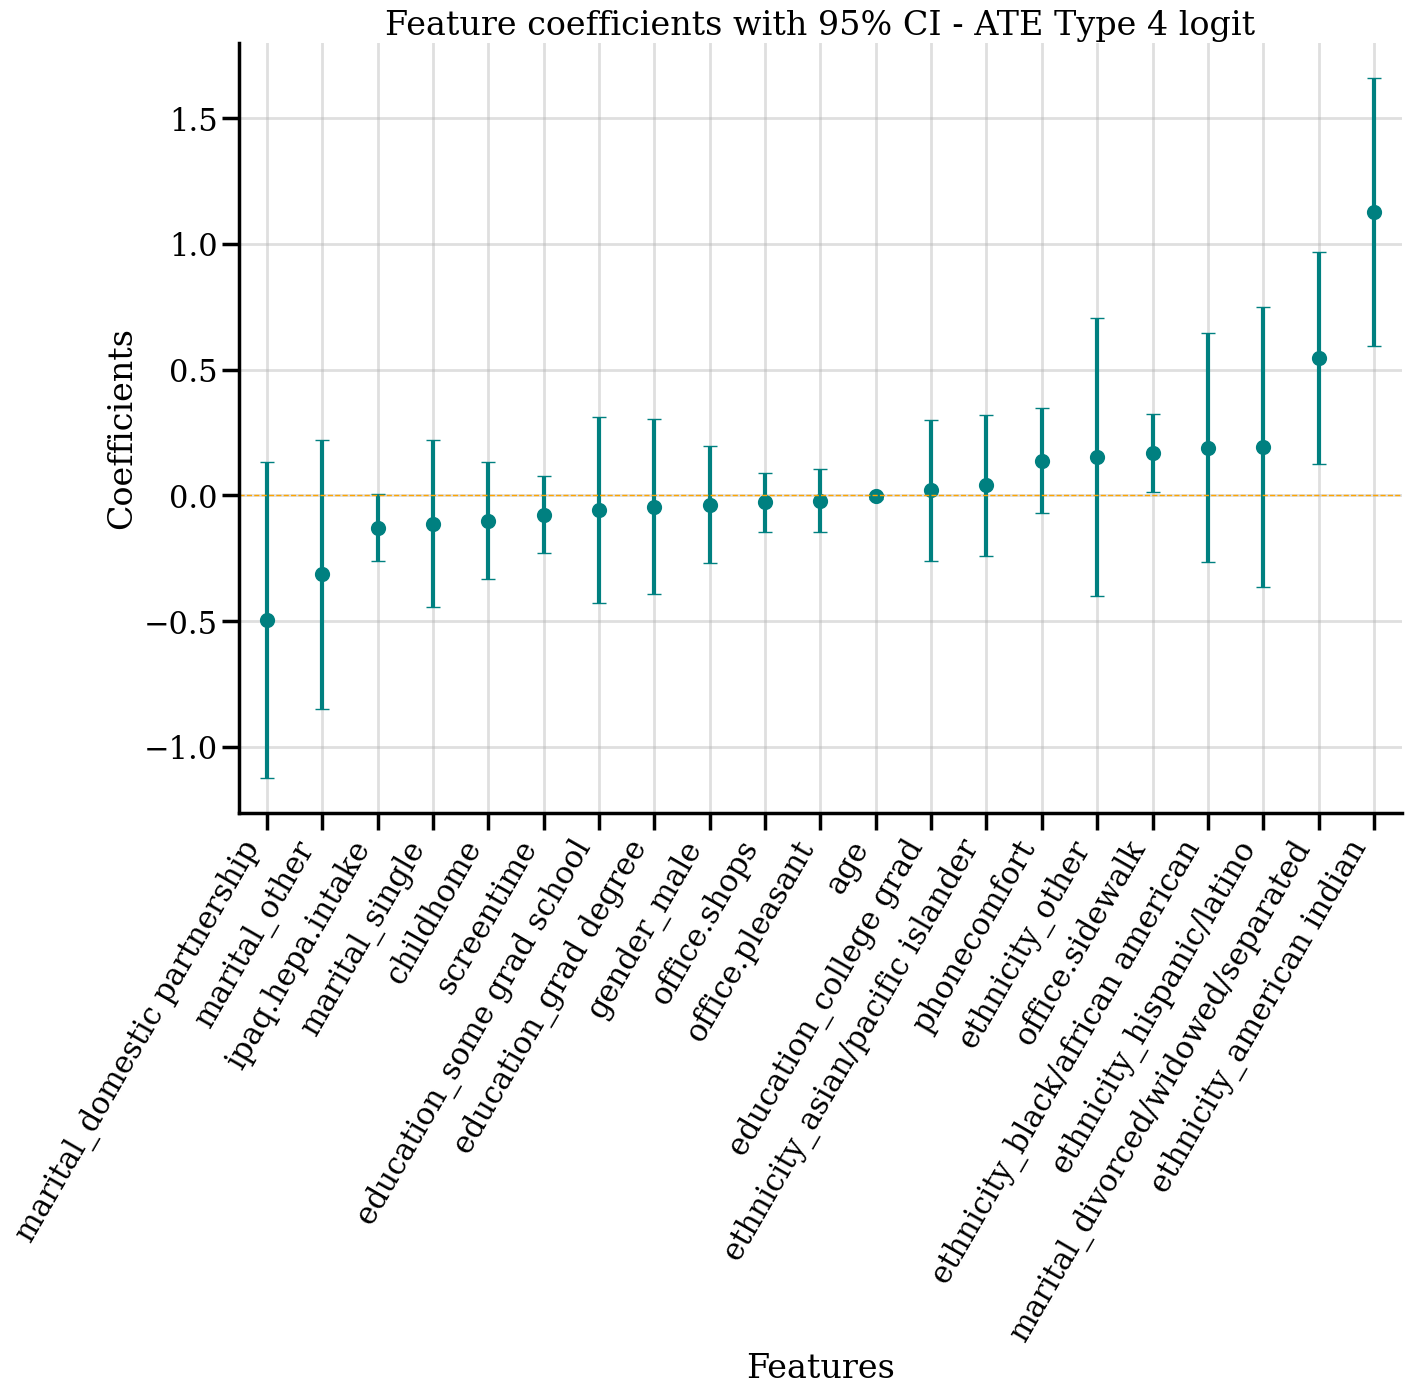

In [160]:
coef_plot(results)